**Install required libraries**

In [1]:
!pip install -q librosa soundfile audiomentations noisereduce xgboost imbalanced-learn seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.1/86.1 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.4/109.4 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.5/248.5 kB 19.2 MB/s eta 0:00:00


**Imports libraries**

In [2]:
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import librosa
import librosa.display
import soundfile as sf

from IPython.display import Audio, display

**Mount Google Drive**

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Set dataset path**

In [4]:
DATASET_PATH = "/content/drive/MyDrive/ser_dataset"

**Check folder structure**

In [5]:
expected_folders = ["Angry", "Happy", "Neutral", "Sad"]

for folder in expected_folders:
    folder_path = os.path.join(DATASET_PATH, folder)
    wav_files = glob.glob(os.path.join(folder_path, "*.wav"))
    print(f"{folder:<10} Exists: {os.path.exists(folder_path)} | WAV files: {len(wav_files)}")

Angry      Exists: True | WAV files: 100
Happy      Exists: True | WAV files: 100
Neutral    Exists: True | WAV files: 100
Sad        Exists: True | WAV files: 100


**Build metadata dataframe**

In [6]:
records = []

for label in expected_folders:
    folder_path = os.path.join(DATASET_PATH, label)
    wav_files = sorted(glob.glob(os.path.join(folder_path, "*.wav")))

    for fp in wav_files:
        records.append({
            "filepath": fp,
            "emotion_label": label,
            "filename": os.path.basename(fp)
        })

df = pd.DataFrame(records)

print("Total files found:", len(df))
df.head()

Total files found: 400


,filepath,emotion_label,filename
0,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,Angry,SM1_F10_A010.wav
1,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,Angry,SM1_F11_A011.wav
2,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,Angry,SM1_F12_A012.wav
3,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,Angry,SM1_F13_A013.wav
4,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,Angry,SM1_F14_A014.wav


**Extract basic audio metadata**

In [7]:
metadata = []

for idx, row in df.iterrows():
    fp = row["filepath"]

    try:
        y, sr = librosa.load(fp, sr=None)
        duration = librosa.get_duration(y=y, sr=sr)

        metadata.append({
            "filepath": fp,
            "filename": row["filename"],
            "emotion_label": row["emotion_label"],
            "sample_rate": sr,
            "duration_sec": duration,
            "num_samples": len(y),
            "min_amplitude": float(np.min(y)),
            "max_amplitude": float(np.max(y)),
            "mean_amplitude": float(np.mean(y)),
            "std_amplitude": float(np.std(y))
        })

    except Exception as e:
        print(f"Error reading file: {fp}")
        print("Reason:", e)

meta_df = pd.DataFrame(metadata)

print("Readable files:", len(meta_df))
meta_df.head()

Readable files: 400


,filepath,filename,emotion_label,sample_rate,duration_sec,num_samples,min_amplitude,max_amplitude,mean_amplitude,std_amplitude
0,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,SM1_F10_A010.wav,Angry,44100,3.003537,132456,-0.398499,0.374237,-0.000040,0.084531
1,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,SM1_F11_A011.wav,Angry,44100,2.000000,88200,-0.492218,0.451508,-0.042356,0.107988
2,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,SM1_F12_A012.wav,Angry,44100,3.003537,132456,-0.527863,0.453064,-0.043681,0.092508
3,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,SM1_F13_A013.wav,Angry,44100,2.000000,88200,-0.586731,0.463226,-0.042833,0.096251
4,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,SM1_F14_A014.wav,Angry,44100,3.003537,132456,-0.489105,0.477570,-0.043117,0.097797


**Check class balance**

In [8]:
print(meta_df["emotion_label"].value_counts())

emotion_label
Angry      100
Happy      100
Neutral    100
Sad        100
Name: count, dtype: int64


**Emotion Class Distribution Plot**

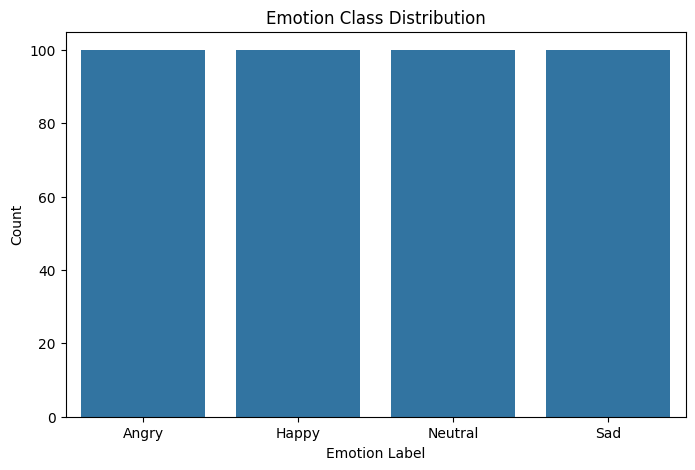

In [9]:
plt.figure(figsize=(8, 5))
sns.countplot(data=meta_df, x="emotion_label", order=sorted(meta_df["emotion_label"].unique()))
plt.title("Emotion Class Distribution")
plt.xlabel("Emotion Label")
plt.ylabel("Count")
plt.show()

**Analyze duration**

In [10]:
print(meta_df["duration_sec"].describe())

count    400.000000
mean       2.496740
std        0.507404
min        0.992109
25%        2.000000
50%        2.000000
75%        3.003537
max        3.003537
Name: duration_sec, dtype: float64


**Distribution of Audio Duration in Histogram Plot**

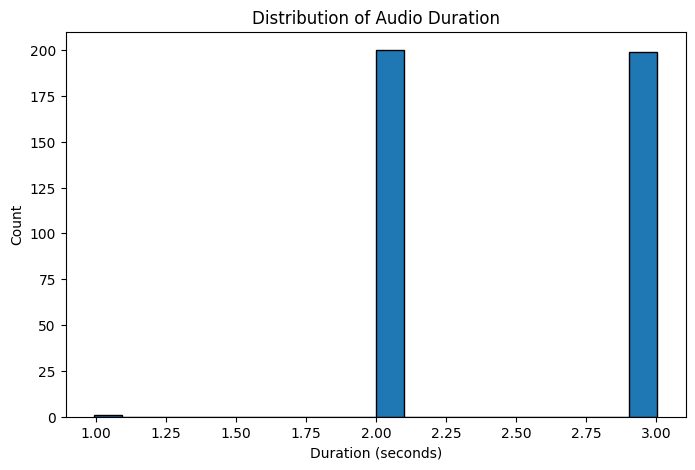

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(meta_df["duration_sec"], bins=20, edgecolor='black')
plt.title("Distribution of Audio Duration")
plt.xlabel("Duration (seconds)")
plt.ylabel("Count")
plt.show()

**Audio Duration by Emotion Class in Boxplot by class**

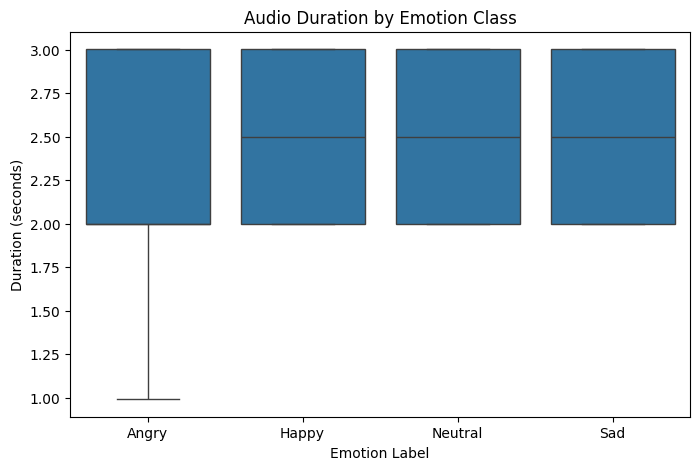

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=meta_df, x="emotion_label", y="duration_sec", order=sorted(meta_df["emotion_label"].unique()))
plt.title("Audio Duration by Emotion Class")
plt.xlabel("Emotion Label")
plt.ylabel("Duration (seconds)")
plt.show()

**Analyze sample rates**

In [13]:
print("Unique sample rates:", sorted(meta_df["sample_rate"].unique()))
print(meta_df["sample_rate"].value_counts())

Unique sample rates: [np.int64(44100)]
sample_rate
44100    400
Name: count, dtype: int64


**Sample Rate Distribution**

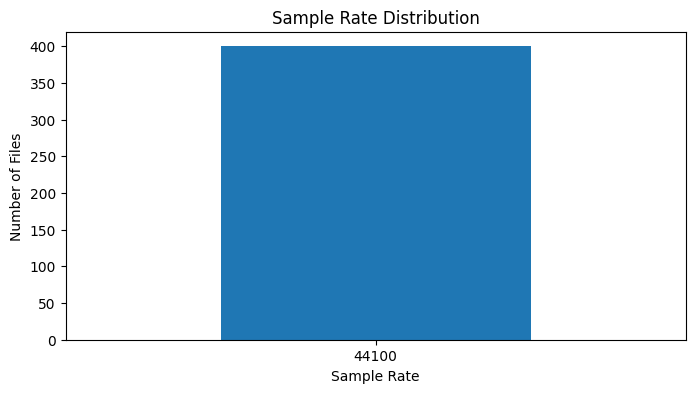

In [14]:
plt.figure(figsize=(8, 4))
meta_df["sample_rate"].value_counts().sort_index().plot(kind="bar")
plt.title("Sample Rate Distribution")
plt.xlabel("Sample Rate")
plt.ylabel("Number of Files")
plt.xticks(rotation=0)
plt.show()

**Listen to one sample from each class**

In [15]:
for label in expected_folders:
    sample = meta_df[meta_df["emotion_label"] == label].iloc[0]
    print(f"\nEmotion: {label} | File: {sample['filename']} | Duration: {sample['duration_sec']:.2f}s")
    display(Audio(sample["filepath"]))


Emotion: Angry | File: SM1_F10_A010.wav | Duration: 3.00s



Emotion: Happy | File: SF1_F10_H010.wav | Duration: 3.00s



Emotion: Neutral | File: SF9_F1_N01.wav | Duration: 2.00s



Emotion: Sad | File: SF10_F1_S01.wav | Duration: 2.00s


**Waveform plots**

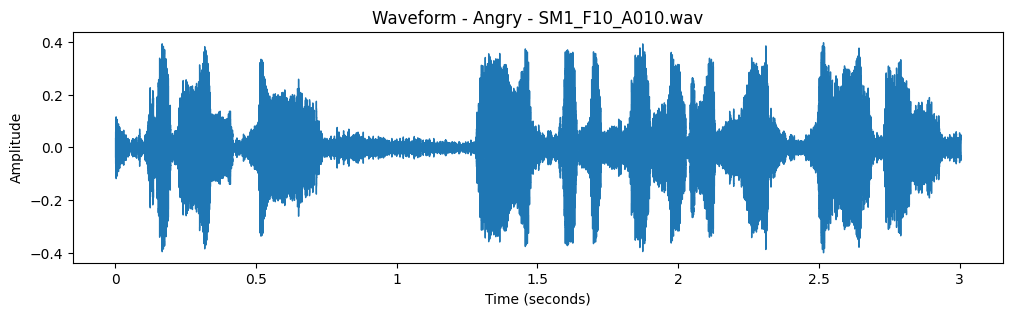

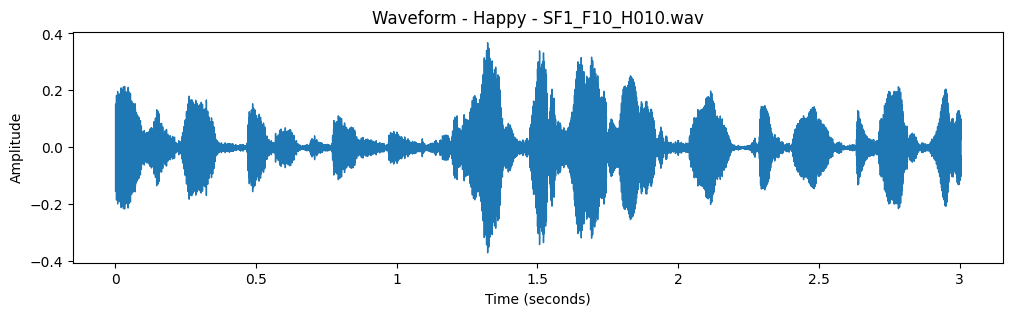

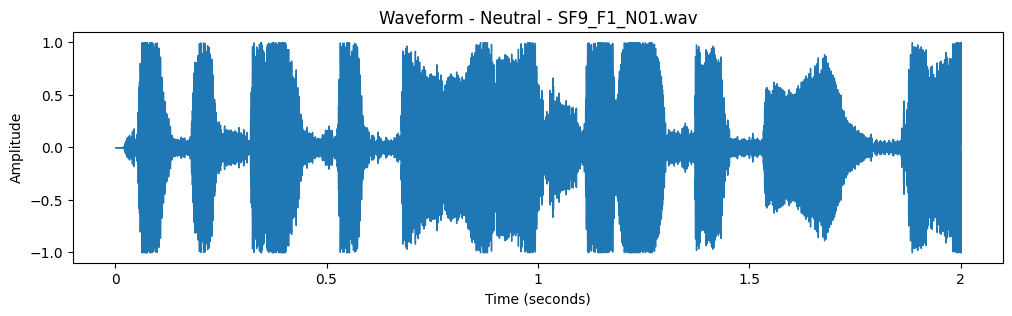

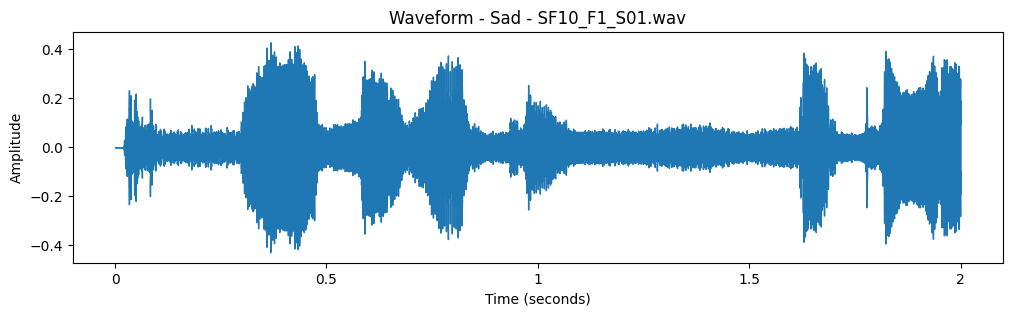

In [16]:
for label in expected_folders:
    sample = meta_df[meta_df["emotion_label"] == label].iloc[0]
    y, sr = librosa.load(sample["filepath"], sr=None)

    plt.figure(figsize=(12, 3))
    librosa.display.waveshow(y, sr=sr)
    plt.title(f"Waveform - {label} - {sample['filename']}")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.show()

**Spectrogram plots**

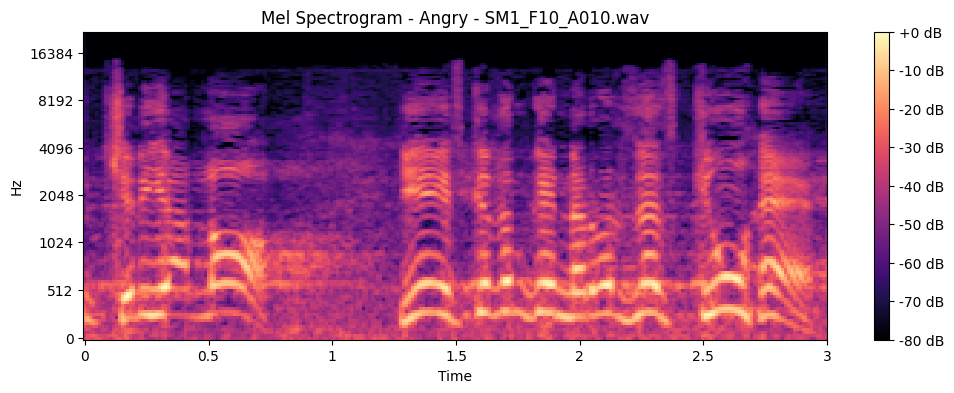

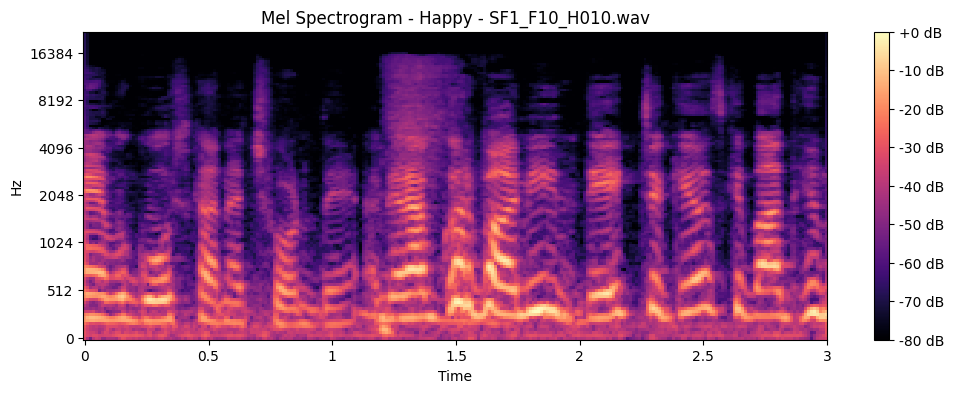

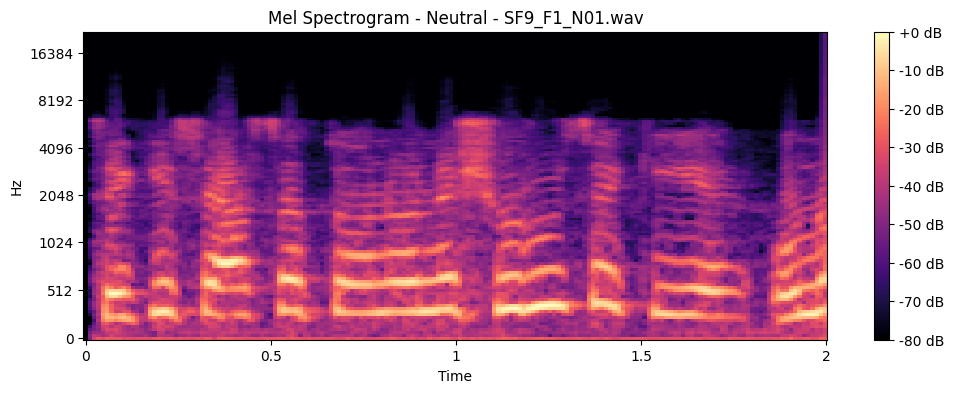

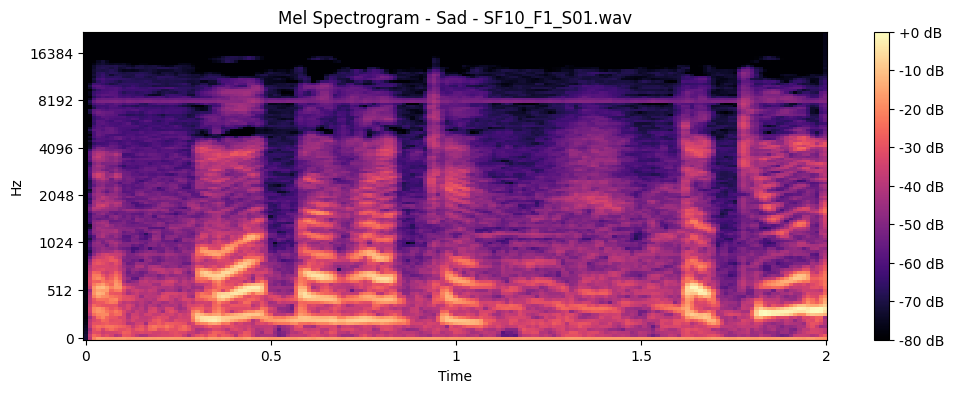

In [17]:
for label in expected_folders:
    sample = meta_df[meta_df["emotion_label"] == label].iloc[0]
    y, sr = librosa.load(sample["filepath"], sr=None)

    mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

    plt.figure(figsize=(12, 4))
    librosa.display.specshow(mel_spec_db, sr=sr, x_axis='time', y_axis='mel')
    plt.colorbar(format='%+2.0f dB')
    plt.title(f"Mel Spectrogram - {label} - {sample['filename']}")
    plt.show()

**Add clinical proxy mapping**

In [18]:
import os
import glob
import pandas as pd

DATASET_PATH = "/content/drive/MyDrive/ser_dataset"

records = []

for label in ["Angry", "Happy", "Neutral", "Sad"]:
    folder_path = os.path.join(DATASET_PATH, label)
    wav_files = glob.glob(os.path.join(folder_path, "*.wav"))

    for fp in wav_files:
        records.append({
            "filepath": fp,
            "emotion_label": label,
            "filename": os.path.basename(fp)
        })

meta_df = pd.DataFrame(records)

print("meta_df created with shape:", meta_df.shape)
meta_df.head()

meta_df created with shape: (400, 3)


,filepath,emotion_label,filename
0,/content/drive/MyDrive/ser_dataset/Angry/SM2_F...,Angry,SM2_F13_A035.wav
1,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,Angry,SM1_F6_A06.wav
2,/content/drive/MyDrive/ser_dataset/Angry/SM2_F...,Angry,SM2_F28_A050.wav
3,/content/drive/MyDrive/ser_dataset/Angry/SM2_F...,Angry,SM2_F23_A045.wav
4,/content/drive/MyDrive/ser_dataset/Angry/SM2_F...,Angry,SM2_F24_A046.wav


**Map data and make dataframe and save file csv**

In [19]:
import os
import glob
import pandas as pd

DATASET_PATH = "/content/drive/MyDrive/ser_dataset"

# Rebuild metadata from scratch
records = []
for label in ["Angry", "Happy", "Neutral", "Sad"]:
    folder_path = os.path.join(DATASET_PATH, label)
    wav_files = glob.glob(os.path.join(folder_path, "*.wav"))
    for fp in wav_files:
        records.append({
            "filepath": fp,
            "emotion_label": label,
            "filename": os.path.basename(fp)
        })

meta_df = pd.DataFrame(records)

# Create mapping from scratch
proxy_df = pd.DataFrame({
    "emotion_label": ["Angry", "Happy", "Neutral", "Sad"],
    "clinical_label": ["anxiety", "healthy", "stress", "depression"]
})

# Merge cleanly
meta_df = meta_df.merge(proxy_df, on="emotion_label", how="left")

# Show result
print(meta_df[["emotion_label", "clinical_label"]].drop_duplicates().sort_values("emotion_label"))
print("\nMissing values:", meta_df["clinical_label"].isna().sum())

# Save files
save_dir = "/content/drive/MyDrive/ser_project"
os.makedirs(save_dir, exist_ok=True)

meta_df.to_csv(os.path.join(save_dir, "metadata_with_clinical_labels.csv"), index=False)
proxy_df.to_csv(os.path.join(save_dir, "clinical_label_mapping.csv"), index=False)

print("\nFiles saved successfully in:", save_dir)

    emotion_label clinical_label
0           Angry        anxiety
100         Happy        healthy
200       Neutral         stress
300           Sad     depression

Missing values: 0

Files saved successfully in: /content/drive/MyDrive/ser_project


**Create project folders**

**Create project folders**

In [20]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ser_project"
PREPROCESSED_DIR = os.path.join(PROJECT_DIR, "preprocessed_audio")
PLOTS_DIR = os.path.join(PROJECT_DIR, "plots")
METADATA_DIR = os.path.join(PROJECT_DIR, "metadata")

os.makedirs(PREPROCESSED_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(METADATA_DIR, exist_ok=True)

print("Project folders ready.")
print("PREPROCESSED_DIR:", PREPROCESSED_DIR)
print("PLOTS_DIR:", PLOTS_DIR)
print("METADATA_DIR:", METADATA_DIR)

Project folders ready.
PREPROCESSED_DIR: /content/drive/MyDrive/ser_project/preprocessed_audio
PLOTS_DIR: /content/drive/MyDrive/ser_project/plots
METADATA_DIR: /content/drive/MyDrive/ser_project/metadata


In [21]:
import os
import glob
import numpy as np
import pandas as pd
import librosa

DATASET_PATH = "/content/drive/MyDrive/ser_dataset"

records = []

for label in ["Angry", "Happy", "Neutral", "Sad"]:
    folder_path = os.path.join(DATASET_PATH, label)
    wav_files = sorted(glob.glob(os.path.join(folder_path, "*.wav")))

    for fp in wav_files:
        try:
            y, sr = librosa.load(fp, sr=None)
            duration = librosa.get_duration(y=y, sr=sr)

            records.append({
                "filepath": fp,
                "filename": os.path.basename(fp),
                "emotion_label": label,
                "sample_rate": sr,
                "duration_sec": duration,
                "num_samples": len(y),
                "min_amplitude": float(np.min(y)),
                "max_amplitude": float(np.max(y)),
                "mean_amplitude": float(np.mean(y)),
                "std_amplitude": float(np.std(y))
            })
        except Exception as e:
            print(f"Error reading {fp}: {e}")

meta_df = pd.DataFrame(records)

print("meta_df shape:", meta_df.shape)
print(meta_df.columns.tolist())
meta_df.head()

meta_df shape: (400, 10)
['filepath', 'filename', 'emotion_label', 'sample_rate', 'duration_sec', 'num_samples', 'min_amplitude', 'max_amplitude', 'mean_amplitude', 'std_amplitude']


,filepath,filename,emotion_label,sample_rate,duration_sec,num_samples,min_amplitude,max_amplitude,mean_amplitude,std_amplitude
0,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,SM1_F10_A010.wav,Angry,44100,3.003537,132456,-0.398499,0.374237,-0.000040,0.084531
1,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,SM1_F11_A011.wav,Angry,44100,2.000000,88200,-0.492218,0.451508,-0.042356,0.107988
2,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,SM1_F12_A012.wav,Angry,44100,3.003537,132456,-0.527863,0.453064,-0.043681,0.092508
3,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,SM1_F13_A013.wav,Angry,44100,2.000000,88200,-0.586731,0.463226,-0.042833,0.096251
4,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,SM1_F14_A014.wav,Angry,44100,3.003537,132456,-0.489105,0.477570,-0.043117,0.097797


In [22]:
proxy_df = pd.DataFrame({
    "emotion_label": ["Angry", "Happy", "Neutral", "Sad"],
    "clinical_label": ["anxiety", "healthy", "stress", "depression"]
})

# remove old clinical_label columns if already present
cols_to_drop = [col for col in meta_df.columns if col.startswith("clinical_label")]
meta_df = meta_df.drop(columns=cols_to_drop, errors="ignore")

meta_df = meta_df.merge(proxy_df, on="emotion_label", how="left")

print(meta_df[["emotion_label", "clinical_label"]].drop_duplicates().sort_values("emotion_label"))
print("\nMissing values:", meta_df["clinical_label"].isna().sum())

    emotion_label clinical_label
0           Angry        anxiety
100         Happy        healthy
200       Neutral         stress
300           Sad     depression

Missing values: 0


**Inspect duration outliers first**

In [23]:
print(meta_df["duration_sec"].describe())

short_files = meta_df[meta_df["duration_sec"] < 1.5].copy()
print("\nShort duration files:")
print(short_files[["filename", "emotion_label", "duration_sec"]].sort_values("duration_sec"))

count    400.000000
mean       2.496740
std        0.507404
min        0.992109
25%        2.000000
50%        2.000000
75%        3.003537
max        3.003537
Name: duration_sec, dtype: float64

Short duration files:
          filename emotion_label  duration_sec
20  SM1_F8_A08.wav         Angry      0.992109


**Preprocessing helper functions**

In [24]:
import numpy as np
import librosa
import soundfile as sf

TARGET_SR = 44100
TARGET_DURATION = 3.0
TARGET_LENGTH = int(TARGET_SR * TARGET_DURATION)

def peak_normalize(y):
    peak = np.max(np.abs(y))
    if peak > 0:
        y = y / peak
    return y

def pad_or_truncate(y, target_length=TARGET_LENGTH):
    if len(y) < target_length:
        pad_width = target_length - len(y)
        y = np.pad(y, (0, pad_width), mode="constant")
    else:
        y = y[:target_length]
    return y

def preprocess_audio(filepath, target_sr=TARGET_SR, target_length=TARGET_LENGTH, top_db=25):
    # load
    y, sr = librosa.load(filepath, sr=target_sr)

    # original duration
    original_duration = librosa.get_duration(y=y, sr=sr)

    # trim leading/trailing silence
    y_trimmed, _ = librosa.effects.trim(y, top_db=top_db)
    trimmed_duration = librosa.get_duration(y=y_trimmed, sr=sr)

    # fallback if trim removes too much or gives empty signal
    if len(y_trimmed) < int(0.3 * sr):
        y_trimmed = y.copy()
        trimmed_duration = original_duration

    # normalize
    y_norm = peak_normalize(y_trimmed)

    # fixed length
    y_fixed = pad_or_truncate(y_norm, target_length=target_length)
    final_duration = librosa.get_duration(y=y_fixed, sr=sr)

    return {
        "y_original": y,
        "y_trimmed": y_trimmed,
        "y_final": y_fixed,
        "sr": sr,
        "original_duration": original_duration,
        "trimmed_duration": trimmed_duration,
        "final_duration": final_duration,
        "original_num_samples": len(y),
        "trimmed_num_samples": len(y_trimmed),
        "final_num_samples": len(y_fixed)
    }

**Test preprocessing on one file from each class**

In [25]:
test_rows = meta_df.groupby("emotion_label").head(1)

for _, row in test_rows.iterrows():
    result = preprocess_audio(row["filepath"])
    print(f"\nEmotion: {row['emotion_label']}")
    print(f"File: {row['filename']}")
    print(f"Original duration: {result['original_duration']:.3f}s")
    print(f"Trimmed duration : {result['trimmed_duration']:.3f}s")
    print(f"Final duration   : {result['final_duration']:.3f}s")
    print(f"Final samples    : {result['final_num_samples']}")


Emotion: Angry
File: SM1_F10_A010.wav
Original duration: 3.004s
Trimmed duration : 3.004s
Final duration   : 3.000s
Final samples    : 132300

Emotion: Happy
File: SF1_F10_H010.wav
Original duration: 3.004s
Trimmed duration : 3.004s
Final duration   : 3.000s
Final samples    : 132300

Emotion: Neutral
File: SF9_F1_N01.wav
Original duration: 2.000s
Trimmed duration : 1.965s
Final duration   : 3.000s
Final samples    : 132300

Emotion: Sad
File: SF10_F1_S01.wav
Original duration: 2.000s
Trimmed duration : 1.988s
Final duration   : 3.000s
Final samples    : 132300


**Plot before vs after waveform**

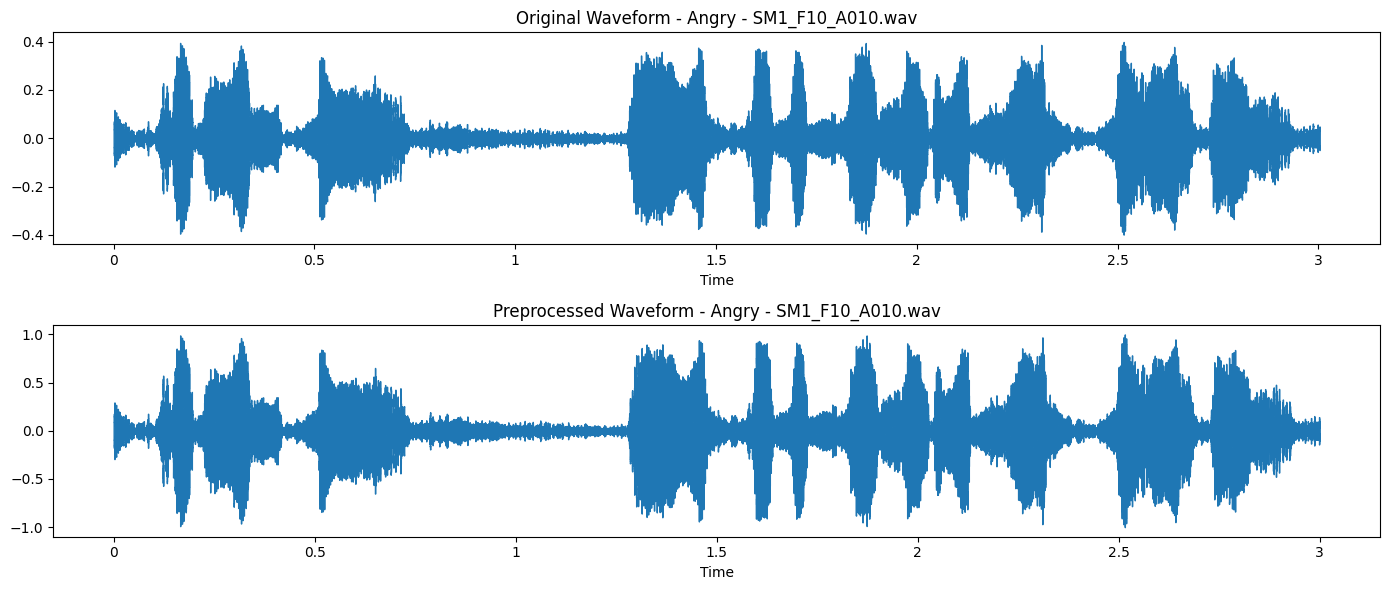

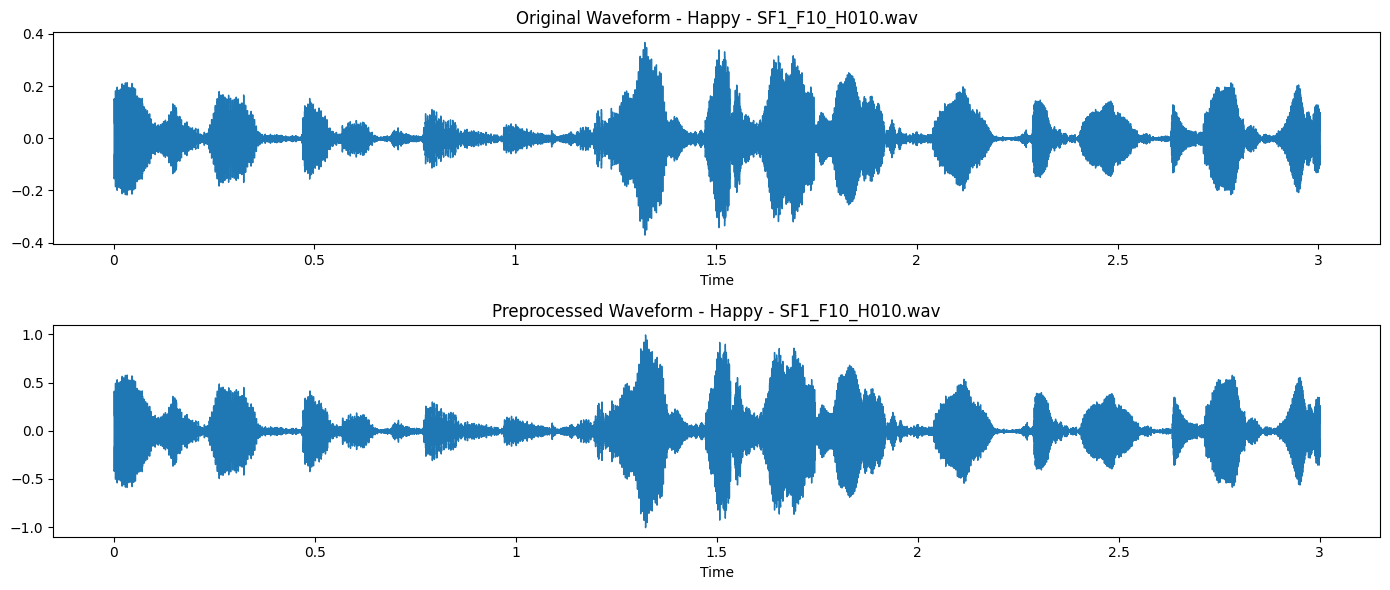

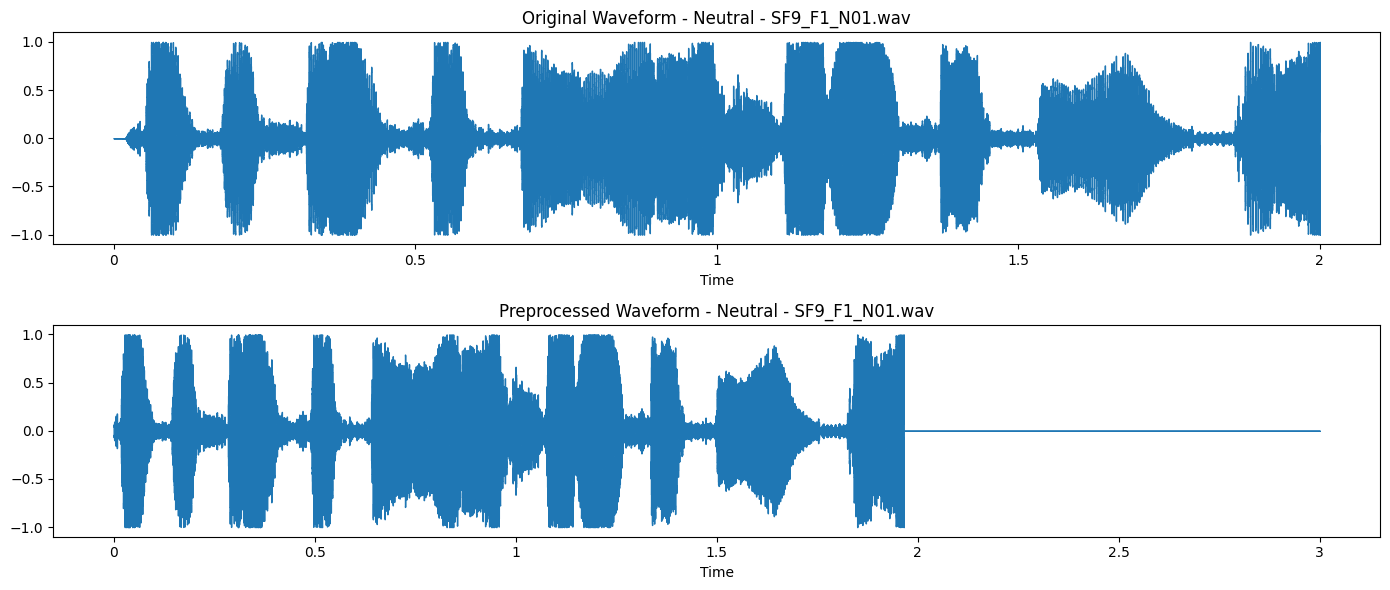

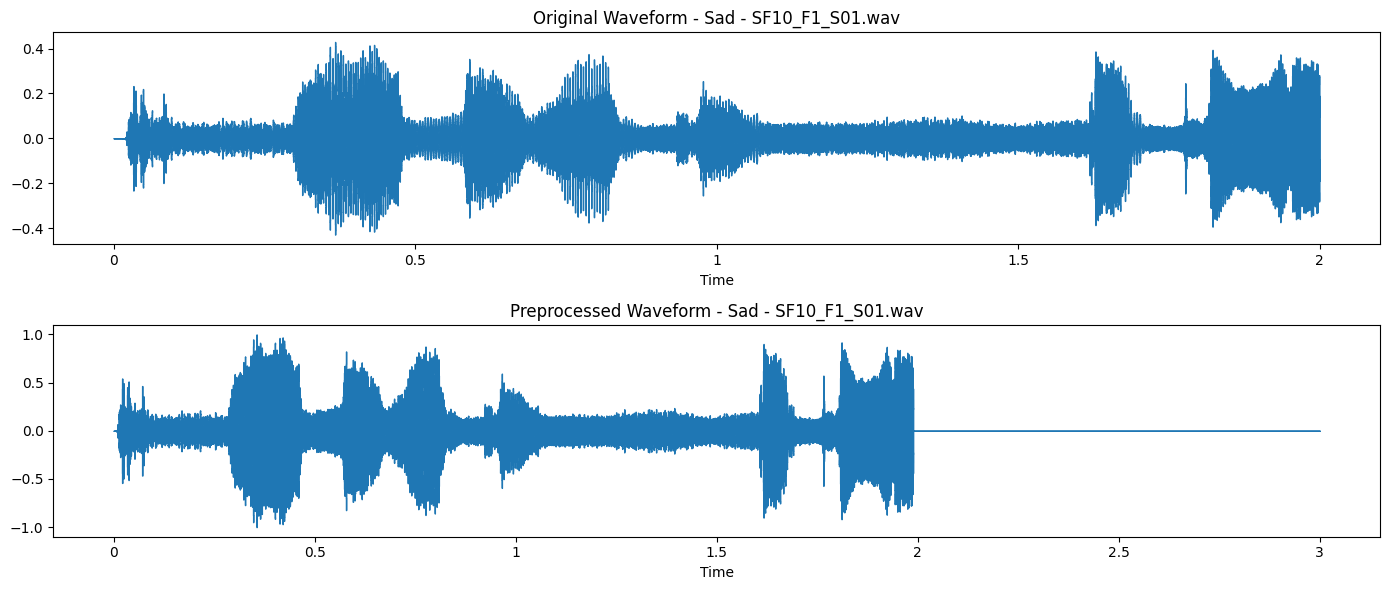

In [26]:
import matplotlib.pyplot as plt
import librosa.display

for _, row in test_rows.iterrows():
    result = preprocess_audio(row["filepath"])

    plt.figure(figsize=(14, 6))

    plt.subplot(2, 1, 1)
    librosa.display.waveshow(result["y_original"], sr=result["sr"])
    plt.title(f"Original Waveform - {row['emotion_label']} - {row['filename']}")

    plt.subplot(2, 1, 2)
    librosa.display.waveshow(result["y_final"], sr=result["sr"])
    plt.title(f"Preprocessed Waveform - {row['emotion_label']} - {row['filename']}")

    plt.tight_layout()
    plt.show()

**Save all preprocessed audio files**

In [27]:
processed_records = []

for idx, row in meta_df.iterrows():
    fp = row["filepath"]
    emotion = row["emotion_label"]
    filename = row["filename"]

    try:
        result = preprocess_audio(fp)

        # create class folder
        class_out_dir = os.path.join(PREPROCESSED_DIR, emotion)
        os.makedirs(class_out_dir, exist_ok=True)

        out_path = os.path.join(class_out_dir, filename)

        # save processed wav
        sf.write(out_path, result["y_final"], result["sr"])

        processed_records.append({
            "original_filepath": fp,
            "processed_filepath": out_path,
            "filename": filename,
            "emotion_label": emotion,
            "clinical_label": row["clinical_label"],
            "sample_rate": result["sr"],
            "original_duration_sec": result["original_duration"],
            "trimmed_duration_sec": result["trimmed_duration"],
            "final_duration_sec": result["final_duration"],
            "original_num_samples": result["original_num_samples"],
            "trimmed_num_samples": result["trimmed_num_samples"],
            "final_num_samples": result["final_num_samples"]
        })

    except Exception as e:
        print(f"Error processing {filename}: {e}")

processed_df = pd.DataFrame(processed_records)

print("Processed files:", len(processed_df))
processed_df.head()

Processed files: 400


,original_filepath,processed_filepath,filename,emotion_label,clinical_label,sample_rate,original_duration_sec,trimmed_duration_sec,final_duration_sec,original_num_samples,trimmed_num_samples,final_num_samples
0,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F10_A010.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300
1,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F11_A011.wav,Angry,anxiety,44100,2.000000,1.988390,3.0,88200,87688,132300
2,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F12_A012.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300
3,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F13_A013.wav,Angry,anxiety,44100,2.000000,1.988390,3.0,88200,87688,132300
4,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F14_A014.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300


**Save processed metadata**

In [28]:
processed_meta_path = os.path.join(METADATA_DIR, "processed_metadata.csv")
processed_df.to_csv(processed_meta_path, index=False)

print("Saved processed metadata to:")
print(processed_meta_path)

Saved processed metadata to:
/content/drive/MyDrive/ser_project/metadata/processed_metadata.csv


**Verify all final durations are exactly 3 seconds**

In [29]:
print(processed_df["final_duration_sec"].describe())
print("\nUnique final sample counts:", processed_df["final_num_samples"].unique())
print("Unique final durations:", processed_df["final_duration_sec"].unique()[:10])

count    400.0
mean       3.0
std        0.0
min        3.0
25%        3.0
50%        3.0
75%        3.0
max        3.0
Name: final_duration_sec, dtype: float64

Unique final sample counts: [132300]
Unique final durations: [3.]


**Compare original vs trimmed durations**

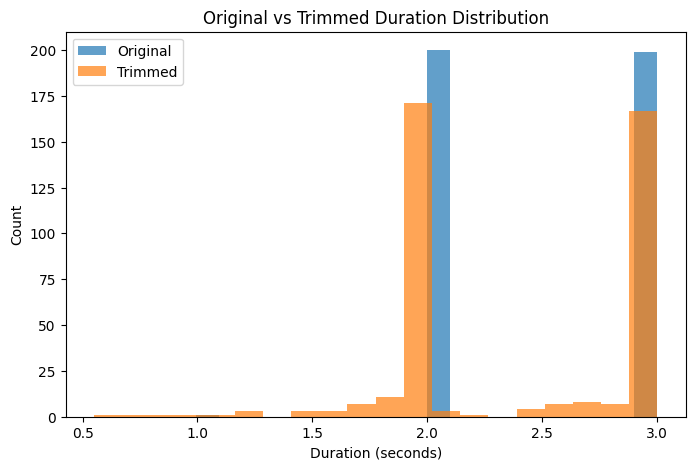

In [30]:
plt.figure(figsize=(8, 5))
plt.hist(processed_df["original_duration_sec"], bins=20, alpha=0.7, label="Original")
plt.hist(processed_df["trimmed_duration_sec"], bins=20, alpha=0.7, label="Trimmed")
plt.title("Original vs Trimmed Duration Distribution")
plt.xlabel("Duration (seconds)")
plt.ylabel("Count")
plt.legend()
plt.show()

**Check how much silence was removed**

count    400.000000
mean       0.081168
std        0.215685
min        0.000000
25%        0.000000
50%        0.011610
75%        0.034830
max        1.947029
Name: silence_removed_sec, dtype: float64


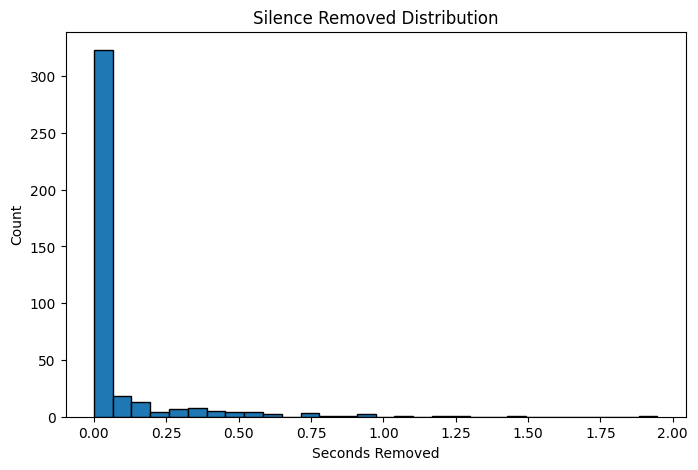

In [31]:
processed_df["silence_removed_sec"] = (
    processed_df["original_duration_sec"] - processed_df["trimmed_duration_sec"]
)

print(processed_df["silence_removed_sec"].describe())

plt.figure(figsize=(8, 5))
plt.hist(processed_df["silence_removed_sec"], bins=30, edgecolor="black")
plt.title("Silence Removed Distribution")
plt.xlabel("Seconds Removed")
plt.ylabel("Count")
plt.show()

**Inspect shortest original file after preprocessing**

original_filepath        /content/drive/MyDrive/ser_dataset/Angry/SM1_F...
processed_filepath       /content/drive/MyDrive/ser_project/preprocesse...
filename                                                    SM1_F8_A08.wav
emotion_label                                                        Angry
clinical_label                                                     anxiety
sample_rate                                                          44100
original_duration_sec                                             0.992109
trimmed_duration_sec                                              0.992109
final_duration_sec                                                     3.0
original_num_samples                                                 43752
trimmed_num_samples                                                  43752
final_num_samples                                                   132300
silence_removed_sec                                                    0.0
Name: 20, dtype: object


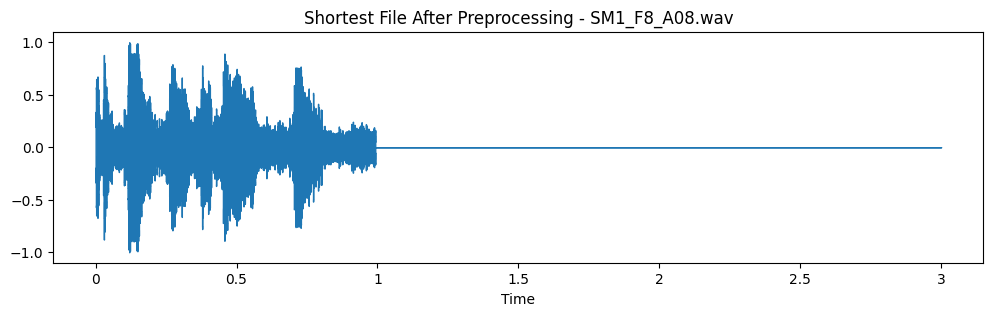

In [32]:
shortest_row = processed_df.sort_values("original_duration_sec").iloc[0]
print(shortest_row)

y_short, sr_short = librosa.load(shortest_row["processed_filepath"], sr=None)

plt.figure(figsize=(12, 3))
librosa.display.waveshow(y_short, sr=sr_short)
plt.title(f"Shortest File After Preprocessing - {shortest_row['filename']}")
plt.show()

**Feature Extraction**

In [ ]:
import numpy as np
import pandas as pd
import librosa

def extract_features_from_trimmed(filepath, top_db=25):
    # Load original audio at native sr
    y, sr = librosa.load(filepath, sr=None)

    # Trim silence
    y_trimmed, _ = librosa.effects.trim(y, top_db=top_db)

    # Fallback if trimming becomes too aggressive
    if len(y_trimmed) < int(0.3 * sr):
        y_trimmed = y.copy()

    # Peak normalize
    peak = np.max(np.abs(y_trimmed))
    if peak > 0:
        y_trimmed = y_trimmed / peak

    features = {}

    
    mfcc = librosa.feature.mfcc(y=y_trimmed, sr=sr, n_mfcc=20)
    for i in range(20):
        features[f"mfcc_{i}_mean"] = np.mean(mfcc[i])
        features[f"mfcc_{i}_std"] = np.std(mfcc[i])

   
    rms = librosa.feature.rms(y=y_trimmed)[0]
    features["rms_mean"] = np.mean(rms)
    features["rms_std"] = np.std(rms)

    
    zcr = librosa.feature.zero_crossing_rate(y_trimmed)[0]
    features["zcr_mean"] = np.mean(zcr)
    features["zcr_std"] = np.std(zcr)

    
    centroid = librosa.feature.spectral_centroid(y=y_trimmed, sr=sr)[0]
    bandwidth = librosa.feature.spectral_bandwidth(y=y_trimmed, sr=sr)[0]
    rolloff = librosa.feature.spectral_rolloff(y=y_trimmed, sr=sr)[0]
    contrast = librosa.feature.spectral_contrast(y=y_trimmed, sr=sr)

    features["centroid_mean"] = np.mean(centroid)
    features["centroid_std"] = np.std(centroid)

    features["bandwidth_mean"] = np.mean(bandwidth)
    features["bandwidth_std"] = np.std(bandwidth)

    features["rolloff_mean"] = np.mean(rolloff)
    features["rolloff_std"] = np.std(rolloff)

    for i in range(contrast.shape[0]):
        features[f"contrast_{i}_mean"] = np.mean(contrast[i])
        features[f"contrast_{i}_std"] = np.std(contrast[i])

    
    f0, voiced_flag, voiced_probs = librosa.pyin(
        y_trimmed,
        fmin=librosa.note_to_hz("C2"),
        fmax=librosa.note_to_hz("C7")
    )

    valid_f0 = f0[~np.isnan(f0)]
    if len(valid_f0) > 0:
        features["pitch_mean"] = np.mean(valid_f0)
        features["pitch_std"] = np.std(valid_f0)
        features["pitch_min"] = np.min(valid_f0)
        features["pitch_max"] = np.max(valid_f0)
    else:
        features["pitch_mean"] = 0.0
        features["pitch_std"] = 0.0
        features["pitch_min"] = 0.0
        features["pitch_max"] = 0.0

    if voiced_flag is not None:
        features["voiced_ratio"] = np.mean(voiced_flag.astype(float))
    else:
        features["voiced_ratio"] = 0.0

    
    trimmed_duration_sec = librosa.get_duration(y=y_trimmed, sr=sr)
    original_duration_sec = librosa.get_duration(y=y, sr=sr)

    features["original_duration_sec"] = original_duration_sec
    features["trimmed_duration_sec"] = trimmed_duration_sec
    features["silence_removed_sec"] = original_duration_sec - trimmed_duration_sec
    features["silence_removed_ratio"] = (
        (original_duration_sec - trimmed_duration_sec) / original_duration_sec
        if original_duration_sec > 0 else 0.0
    )

    return features

**Build feature dataset**

In [34]:
feature_rows_v2 = []

for idx, row in meta_df.iterrows():
    try:
        feats = extract_features_from_trimmed(row["filepath"], top_db=25)
        feats["emotion_label"] = row["emotion_label"]
        feats["clinical_label"] = row["clinical_label"]
        feats["filename"] = row["filename"]
        feature_rows_v2.append(feats)
    except Exception as e:
        print("Error extracting features from:", row["filename"], "|", e)

features_df_v2 = pd.DataFrame(feature_rows_v2)

print("features_df_v2 shape:", features_df_v2.shape)
print("Total NaN values:", features_df_v2.isna().sum().sum())
features_df_v2.head()

features_df_v2 shape: (400, 76)
Total NaN values: 0


,mfcc_0_mean,mfcc_0_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,...,pitch_min,pitch_max,voiced_ratio,original_duration_sec,trimmed_duration_sec,silence_removed_sec,silence_removed_ratio,emotion_label,clinical_label,filename
0,-188.900726,55.254333,161.231323,26.241289,-28.984278,28.951038,32.058571,21.916744,-7.755405,20.789532,...,97.434427,167.694673,0.656371,3.003537,3.003537,0.00000,0.000000,Angry,anxiety,SM1_F10_A010.wav
1,-195.019577,48.616825,175.105133,20.530874,-25.151487,25.513826,19.775192,13.074556,-11.444435,17.269133,...,102.633629,158.282694,0.988372,2.000000,1.988390,0.01161,0.005805,Angry,anxiety,SM1_F11_A011.wav
2,-203.697723,59.067535,168.339828,22.878414,-39.473392,26.983023,25.777185,20.512844,6.108107,19.245689,...,76.888346,272.420799,0.648649,3.003537,3.003537,0.00000,0.000000,Angry,anxiety,SM1_F12_A012.wav
3,-215.983734,65.321907,161.330322,23.114046,-42.252758,33.315891,32.426479,21.630705,7.660244,18.827000,...,65.785287,176.643034,0.715116,2.000000,1.988390,0.01161,0.005805,Angry,anxiety,SM1_F13_A013.wav
4,-204.183853,64.339775,165.089890,24.818001,-36.107956,30.155386,20.125227,17.588964,3.274971,17.838722,...,97.998859,251.258115,0.803089,3.003537,3.003537,0.00000,0.000000,Angry,anxiety,SM1_F14_A014.wav


**Save features**

In [35]:
features_v2_path = "/content/drive/MyDrive/ser_project/features_v2_trimmed.csv"
features_df_v2.to_csv(features_v2_path, index=False)
print("Saved corrected features to:", features_v2_path)

Saved corrected features to: /content/drive/MyDrive/ser_project/features_v2_trimmed.csv


**Quick intell check**

In [36]:
print(features_df_v2["emotion_label"].value_counts())
print(features_df_v2[["original_duration_sec", "trimmed_duration_sec", "silence_removed_ratio"]].describe())

emotion_label
Angry      100
Happy      100
Neutral    100
Sad        100
Name: count, dtype: int64
       original_duration_sec  trimmed_duration_sec  silence_removed_ratio
count             400.000000            400.000000             400.000000
mean                2.496740              2.415572               0.033320
std                 0.507404              0.545277               0.088785
min                 0.992109              0.548753               0.000000
25%                 2.000000              1.988390               0.000000
50%                 2.000000              2.000000               0.005805
75%                 3.003537              3.003537               0.014314
max                 3.003537              3.003537               0.725624


In [ ]:
print("Duplicate column names:", features_df_v2.columns.duplicated().sum())

constant_cols = [col for col in features_df_v2.columns if features_df_v2[col].nunique() <= 1]
print("Constant columns:", constant_cols)
print("Number of constant columns:", len(constant_cols))

Duplicate column names: 0
Constant columns: []
Number of constant columns: 0


### **Classical ML model training and evaluation**

**Imports Libraries**

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

**Prepare X and y**

In [39]:
df_model = features_df_v2.copy()

non_feature_cols = ["emotion_label", "clinical_label", "filename"]
feature_cols = [col for col in df_model.columns if col not in non_feature_cols]

X = df_model[feature_cols]
y = df_model["clinical_label"]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Target classes:", list(label_encoder.classes_))
print("Number of features:", len(feature_cols))
print("X shape:", X.shape)
print("y shape:", y_encoded.shape)

Target classes: ['anxiety', 'depression', 'healthy', 'stress']
Number of features: 73
X shape: (400, 73)
y shape: (400,)


**Train/test split**

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTrain class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Train shape: (320, 73)
Test shape: (80, 73)

Train class distribution:
0    80
1    80
2    80
3    80
Name: count, dtype: int64

Test class distribution:
0    20
1    20
2    20
3    20
Name: count, dtype: int64


**Define models**

In [41]:
models = {
    "LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=3000, random_state=42))
    ]),

    "SVM_RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", probability=True, random_state=42))
    ]),

    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42
    )
}

**Train and compare models**

In [42]:
results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1_Score": f1
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("F1_Score", ascending=False).reset_index(drop=True)

print("\nModel Comparison:")
print(results_df)

Training LogisticRegression...
Training SVM_RBF...
Training RandomForest...
Training XGBoost...

Model Comparison:
                Model  Accuracy  Precision  Recall  F1_Score
0             SVM_RBF    0.9125   0.915414  0.9125  0.913383
1        RandomForest    0.8875   0.890351  0.8875  0.888368
2             XGBoost    0.8750   0.878708  0.8750  0.876099
3  LogisticRegression    0.8375   0.836905  0.8375  0.836393


**Plot model comparison**

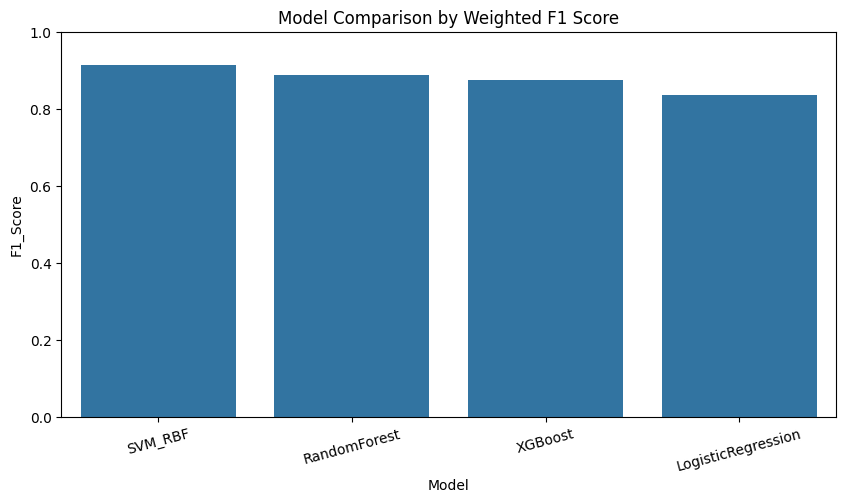

In [43]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="F1_Score")
plt.title("Model Comparison by Weighted F1 Score")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()

**Detailed evaluation of best model**

In [44]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred_best = best_model.predict(X_test)

print("Best Model:", best_model_name)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_best, target_names=label_encoder.classes_))

Best Model: SVM_RBF

Classification Report:

              precision    recall  f1-score   support

     anxiety       1.00      0.95      0.97        20
  depression       0.86      0.90      0.88        20
     healthy       0.86      0.90      0.88        20
      stress       0.95      0.90      0.92        20

    accuracy                           0.91        80
   macro avg       0.92      0.91      0.91        80
weighted avg       0.92      0.91      0.91        80



**Confusion matrix**

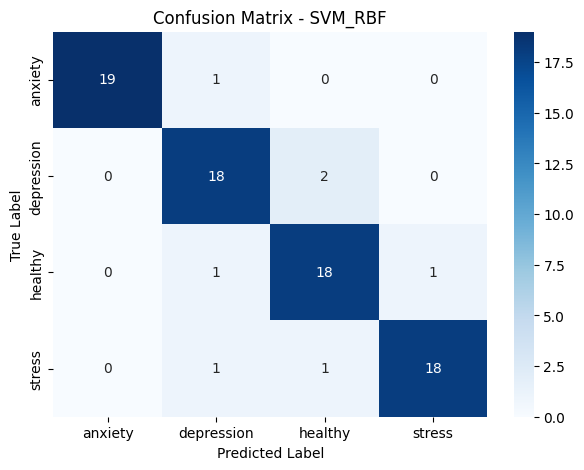

In [45]:
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

**Cross-validation on the best model**

In [46]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    best_model,
    X,
    y_encoded,
    cv=cv,
    scoring="f1_weighted"
)

print("Cross-validation F1 scores:", cv_scores)
print("Mean CV F1:", cv_scores.mean())
print("Std CV F1:", cv_scores.std())

Cross-validation F1 scores: [0.95029706 0.90054945 0.98749218 0.96247655 0.96247655]
Mean CV F1: 0.9526583579022605
Std CV F1: 0.028730134011574572


**Control Overfitting**

**Add regularization tuning**

In [47]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

param_grid = {
    "clf__C": [0.1, 1, 5, 10],
    "clf__gamma": ["scale", 0.01, 0.1, 1]
}

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf", probability=True, random_state=42))
])

grid = GridSearchCV(
    svm_pipeline,
    param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV score:", grid.best_score_)

best_svm = grid.best_estimator_

y_pred_tuned = best_svm.predict(X_test)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_tuned, target_names=label_encoder.classes_))

Best params: {'clf__C': 10, 'clf__gamma': 'scale'}
Best CV score: 0.956386320404388
              precision    recall  f1-score   support

     anxiety       1.00      0.95      0.97        20
  depression       0.86      0.95      0.90        20
     healthy       0.82      0.90      0.86        20
      stress       0.94      0.80      0.86        20

    accuracy                           0.90        80
   macro avg       0.91      0.90      0.90        80
weighted avg       0.91      0.90      0.90        80



**Feature Scaling**

In [48]:
rf_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=42))
])

**Remove low-importance features**

In [49]:
rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_train, y_train)

importances = rf.feature_importances_
feat_importance = pd.Series(importances, index=feature_cols).sort_values(ascending=False)

print(feat_importance.head(15))

contrast_6_mean    0.064243
contrast_5_mean    0.051119
bandwidth_mean     0.044285
mfcc_4_mean        0.034125
contrast_5_std     0.033112
mfcc_2_mean        0.031573
centroid_mean      0.031079
pitch_mean         0.030182
mfcc_14_mean       0.027577
contrast_3_mean    0.024807
mfcc_13_mean       0.024530
rms_std            0.023905
mfcc_10_mean       0.022736
mfcc_3_mean        0.022541
contrast_4_mean    0.022344
dtype: float64


In [ ]:
svm_original = trained_models["SVM_RBF"]

y_pred_orig = svm_original.predict(X_test)

from sklearn.metrics import f1_score

f1_orig = f1_score(y_test, y_pred_orig, average="weighted")

y_pred_tuned = best_svm.predict(X_test)
f1_tuned = f1_score(y_test, y_pred_tuned, average="weighted")

print("=== Regularization Effect ===")
print("Before tuning F1:", f1_orig)
print("After tuning F1 :", f1_tuned)
print("Difference      :", f1_tuned - f1_orig)

=== Regularization Effect ===
Before tuning F1: 0.913383364602877
After tuning F1 : 0.9002821502821501
Difference      : -0.013101214320726862


**Save Results**

In [51]:
results_save = results_df.copy()
results_save["Best_Model"] = results_df.iloc[0]["Model"]
results_save["Best_CV_F1"] = 0.956386320404388

results_save_path = "/content/drive/MyDrive/ser_project/final_model_results.csv"
results_save.to_csv(results_save_path, index=False)

print("Saved final results to:", results_save_path)

Saved final results to: /content/drive/MyDrive/ser_project/final_model_results.csv


**Plot Feature Importance**

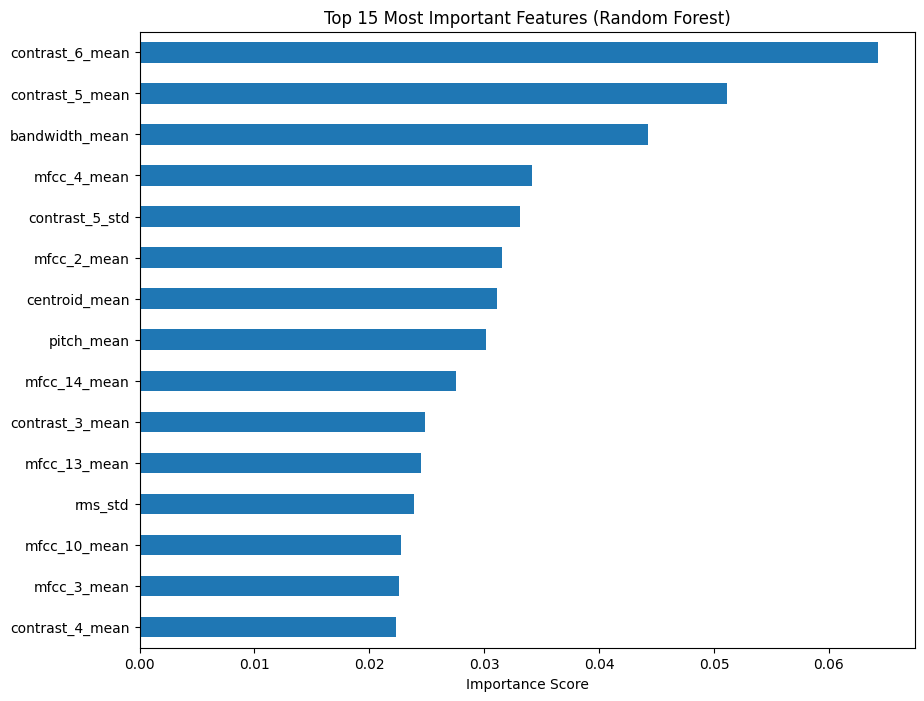

In [52]:
import matplotlib.pyplot as plt

feat_importance = feat_importance.sort_values(ascending=True)

plt.figure(figsize=(10, 8))
feat_importance.tail(15).plot(kind="barh")
plt.title("Top 15 Most Important Features (Random Forest)")
plt.xlabel("Importance Score")
plt.show()

**Permutation Importance**

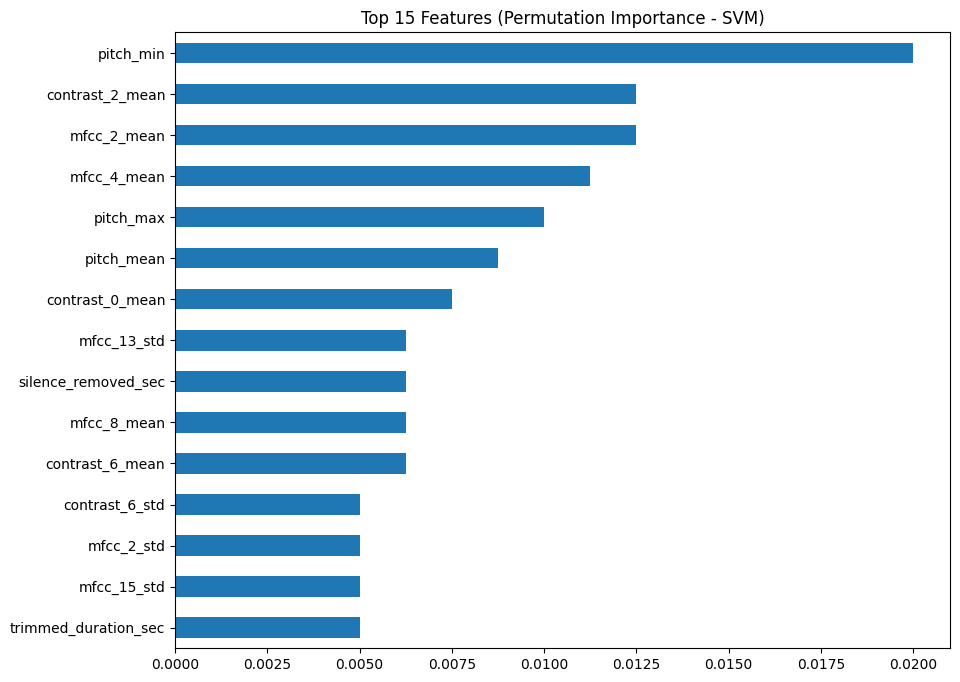

In [53]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    best_svm,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.Series(
    perm_importance.importances_mean,
    index=feature_cols
).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
perm_df.head(15).plot(kind="barh")
plt.title("Top 15 Features (Permutation Importance - SVM)")
plt.gca().invert_yaxis()
plt.show()

**Error Analysis**

In [54]:
errors = X_test.copy()
errors["true"] = y_test
errors["pred"] = best_svm.predict(X_test)

errors["true"] = label_encoder.inverse_transform(errors["true"])
errors["pred"] = label_encoder.inverse_transform(errors["pred"])

misclassified = errors[errors["true"] != errors["pred"]]

print("Total misclassified:", len(misclassified))
misclassified.head()

Total misclassified: 8


,mfcc_0_mean,mfcc_0_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,...,pitch_std,pitch_min,pitch_max,voiced_ratio,original_duration_sec,trimmed_duration_sec,silence_removed_sec,silence_removed_ratio,true,pred
152,-195.585602,80.590805,222.106903,37.482662,-16.466654,41.391655,-2.581040,15.050317,32.039337,18.281927,...,6.190228,65.406391,87.812822,0.623762,2.000000,1.164082,0.835918,0.417959,healthy,depression
304,-249.831558,47.763607,165.064011,24.457848,13.261613,30.587658,45.756207,19.442698,-9.221040,19.812639,...,27.130663,109.366447,207.652349,0.981928,2.000000,1.915646,0.084354,0.042177,depression,healthy
275,-244.001541,56.632320,172.490967,27.435284,2.836421,24.585546,35.831314,13.899464,17.205544,17.295298,...,12.059683,65.406391,103.228180,0.572254,2.000000,2.000000,0.000000,0.000000,stress,healthy
51,-395.616089,94.078239,117.469902,39.353466,22.760923,26.805948,8.716222,11.233569,-0.991121,18.379503,...,10.819199,74.269247,124.186085,0.719368,3.003537,2.933878,0.069660,0.023193,anxiety,depression
290,-264.602051,58.492901,170.544846,27.459578,5.271154,25.746626,43.759087,10.614223,-0.866893,17.469110,...,6.555459,95.209022,126.356819,0.942197,2.000000,2.000000,0.000000,0.000000,stress,healthy


**Analyze confusion patterns**

In [55]:
print(misclassified[["true", "pred"]].value_counts())

true        pred      
stress      healthy       3
anxiety     depression    1
depression  healthy       1
healthy     depression    1
            stress        1
stress      depression    1
Name: count, dtype: int64


**Save FINAL model**

In [56]:
import joblib

final_model = trained_models["SVM_RBF"]   # original best-performing SVM
final_model_path = "/content/drive/MyDrive/ser_project/final_svm_rbf_model.pkl"
joblib.dump(final_model, final_model_path)

print("Final original SVM model saved at:", final_model_path)

Final original SVM model saved at: /content/drive/MyDrive/ser_project/final_svm_rbf_model.pkl


**save label encoder**

In [57]:
le_path = "/content/drive/MyDrive/ser_project/label_encoder.pkl"
joblib.dump(label_encoder, le_path)

print("Label encoder saved at:", le_path)

Label encoder saved at: /content/drive/MyDrive/ser_project/label_encoder.pkl


In [58]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model_Version": ["Original SVM_RBF", "Tuned/Regularized SVM"],
    "Weighted_F1": [0.913383364602877, 0.9002821502821501]
})

comparison_path = "/content/drive/MyDrive/ser_project/svm_regularization_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("Comparison table saved at:", comparison_path)
print(comparison_df)

Comparison table saved at: /content/drive/MyDrive/ser_project/svm_regularization_comparison.csv
           Model_Version  Weighted_F1
0       Original SVM_RBF     0.913383
1  Tuned/Regularized SVM     0.900282


**CNN spectrograms**

In [59]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.utils import to_categorical

**Load processed metadata**

In [60]:
processed_meta_path = "/content/drive/MyDrive/ser_project/metadata/processed_metadata.csv"
processed_df = pd.read_csv(processed_meta_path)

print(processed_df.shape)
processed_df.head()

(400, 12)


,original_filepath,processed_filepath,filename,emotion_label,clinical_label,sample_rate,original_duration_sec,trimmed_duration_sec,final_duration_sec,original_num_samples,trimmed_num_samples,final_num_samples
0,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F10_A010.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300
1,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F11_A011.wav,Angry,anxiety,44100,2.000000,1.988390,3.0,88200,87688,132300
2,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F12_A012.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300
3,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F13_A013.wav,Angry,anxiety,44100,2.000000,1.988390,3.0,88200,87688,132300
4,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F14_A014.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300


**Create spectrogram extraction function**

In [61]:
SR = 44100
N_MELS = 128
HOP_LENGTH = 512
N_FFT = 2048

def extract_log_mel_spectrogram(filepath, sr=SR, n_mels=N_MELS, hop_length=HOP_LENGTH, n_fft=N_FFT):
    y, sr = librosa.load(filepath, sr=sr)

    mel_spec = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels
    )

    log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

    return log_mel_spec

**Build spectrogram dataset**

In [62]:
X_specs = []
y_labels = []
filenames = []

for _, row in processed_df.iterrows():
    try:
        spec = extract_log_mel_spectrogram(row["processed_filepath"])
        X_specs.append(spec)
        y_labels.append(row["clinical_label"])
        filenames.append(row["filename"])
    except Exception as e:
        print("Error:", row["filename"], e)

X_specs = np.array(X_specs)
y_labels = np.array(y_labels)

print("X_specs shape:", X_specs.shape)
print("y_labels shape:", y_labels.shape)

X_specs shape: (400, 128, 259)
y_labels shape: (400,)


**Visual sanity check**

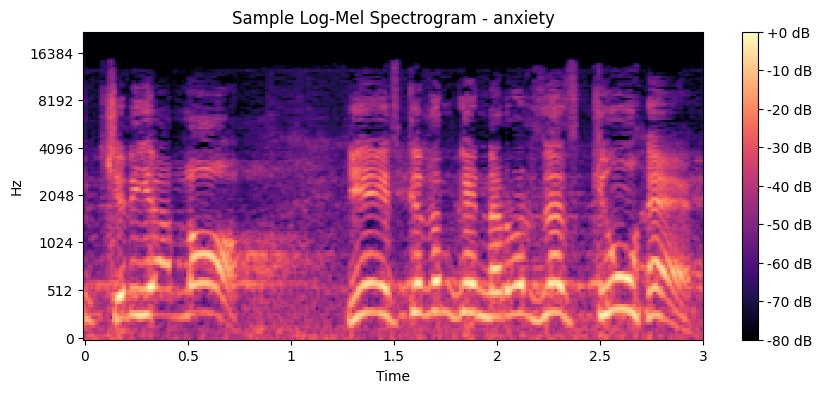

In [63]:
plt.figure(figsize=(10, 4))
librosa.display.specshow(X_specs[0], x_axis="time", y_axis="mel", sr=SR, hop_length=HOP_LENGTH)
plt.colorbar(format="%+2.0f dB")
plt.title(f"Sample Log-Mel Spectrogram - {y_labels[0]}")
plt.show()

**Normalize and reshape for CNN**

In [ ]:
X_specs = (X_specs - X_specs.mean()) / (X_specs.std() + 1e-8)


X_specs = X_specs[..., np.newaxis]

label_encoder_cnn = LabelEncoder()
y_encoded_cnn = label_encoder_cnn.fit_transform(y_labels)
y_cat = to_categorical(y_encoded_cnn)

print("Normalized X shape:", X_specs.shape)
print("y_cat shape:", y_cat.shape)
print("Classes:", label_encoder_cnn.classes_)

Normalized X shape: (400, 128, 259, 1)
y_cat shape: (400, 4)
Classes: ['anxiety' 'depression' 'healthy' 'stress']


**Train/validation/test split**

In [65]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X_specs, y_cat,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded_cnn
)

y_temp_labels = np.argmax(y_temp, axis=1)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,   # 0.25 of 0.8 = 0.2 total
    random_state=42,
    stratify=y_temp_labels
)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (240, 128, 259, 1) (240, 4)
Val  : (80, 128, 259, 1) (80, 4)
Test : (80, 128, 259, 1) (80, 4)


**Build a compact CNN**

In [66]:
input_shape = X_train.shape[1:]
num_classes = y_train.shape[1]

cnn_model = models.Sequential([
    layers.Input(shape=input_shape),

    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    layers.Conv2D(128, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.35),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),

    layers.Dense(num_classes, activation="softmax")
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 259, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 259, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 259, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 129, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 129, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 129, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 129, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 129, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,596 (432.02 KB)

 Trainable params: 110,148 (430.27 KB)

 Non-trainable params: 448 (1.75 KB)

**Callbacks to avoid overfitting**

In [67]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

**Train the CNN**

In [68]:
history = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=16,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - accuracy: 0.3083 - loss: 1.4523 - val_accuracy: 0.2500 - val_loss: 1.3611 - learning_rate: 0.0010
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3833 - loss: 1.2402 - val_accuracy: 0.2375 - val_loss: 1.3948 - learning_rate: 0.0010
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.4833 - loss: 1.1737 - val_accuracy: 0.2500 - val_loss: 1.7302 - learning_rate: 0.0010
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5375 - loss: 1.0738 - val_accuracy: 0.2500 - val_loss: 2.3458 - learning_rate: 0.0010
Epoch 5/50
13/15 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.4997 - loss: 1.1175
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5250 - loss: 1.0524 - val_accuracy: 0.2500 - val_loss: 3.0035 - learning_rate: 0.0010
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5542 - loss: 0.9888 - val_acc

**Plot training curves**

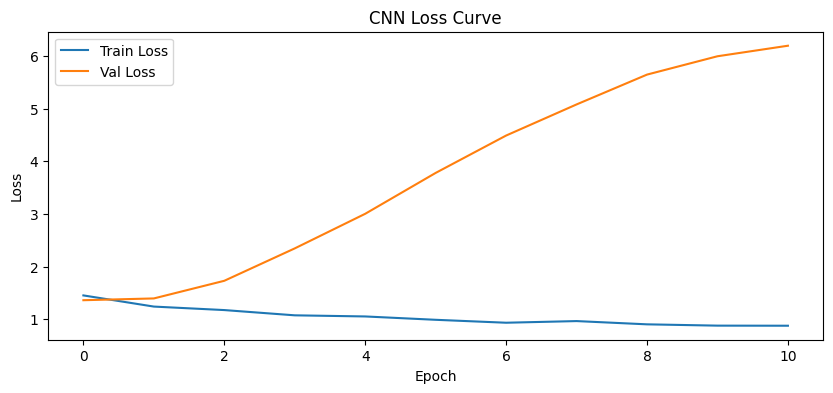

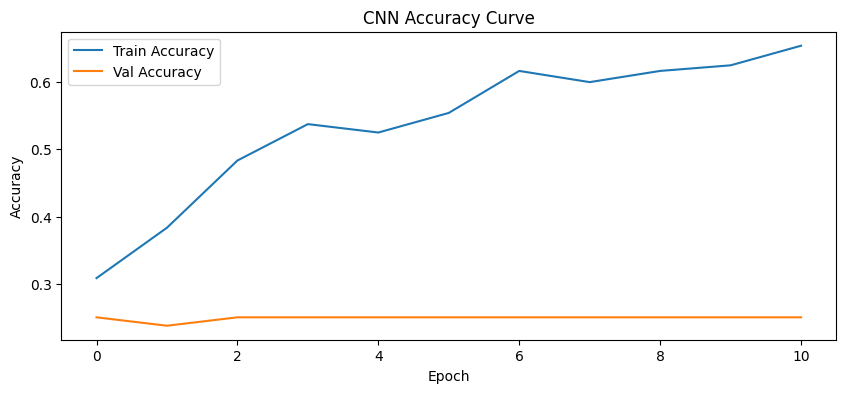

In [69]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("CNN Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.title("CNN Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

**Evaluate on test set**

In [70]:
test_loss, test_acc = cnn_model.evaluate(X_test, y_test, verbose=0)
print("CNN Test Accuracy:", test_acc)
print("CNN Test Loss:", test_loss)

CNN Test Accuracy: 0.25
CNN Test Loss: 1.376577615737915


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 369ms/step
              precision    recall  f1-score   support

     anxiety       0.00      0.00      0.00        20
  depression       0.00      0.00      0.00        20
     healthy       0.25      1.00      0.40        20
      stress       0.00      0.00      0.00        20

    accuracy                           0.25        80
   macro avg       0.06      0.25      0.10        80
weighted avg       0.06      0.25      0.10        80



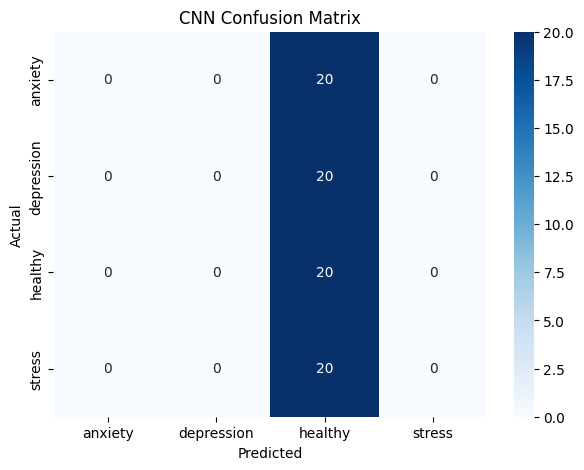

In [71]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_pred_probs = cnn_model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred, target_names=label_encoder_cnn.classes_))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder_cnn.classes_,
    yticklabels=label_encoder_cnn.classes_
)
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [72]:
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.utils import to_categorical

In [73]:
processed_meta_path = "/content/drive/MyDrive/ser_project/metadata/processed_metadata.csv"
processed_df = pd.read_csv(processed_meta_path)

print(processed_df.shape)
processed_df.head()

(400, 12)


,original_filepath,processed_filepath,filename,emotion_label,clinical_label,sample_rate,original_duration_sec,trimmed_duration_sec,final_duration_sec,original_num_samples,trimmed_num_samples,final_num_samples
0,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F10_A010.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300
1,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F11_A011.wav,Angry,anxiety,44100,2.000000,1.988390,3.0,88200,87688,132300
2,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F12_A012.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300
3,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F13_A013.wav,Angry,anxiety,44100,2.000000,1.988390,3.0,88200,87688,132300
4,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F14_A014.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300


In [74]:
SR = 16000
N_MELS = 64
HOP_LENGTH = 256
N_FFT = 1024

def extract_log_mel_spectrogram(filepath, sr=SR, n_mels=N_MELS, hop_length=HOP_LENGTH, n_fft=N_FFT):
    y, _ = librosa.load(filepath, sr=sr)

    mel_spec = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels
    )
    log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
    return log_mel_spec

**Rebuild spectrogram dataset**

In [75]:
X_specs = []
y_labels = []
filenames = []

for _, row in processed_df.iterrows():
    try:
        spec = extract_log_mel_spectrogram(row["processed_filepath"])
        X_specs.append(spec)
        y_labels.append(row["clinical_label"])
        filenames.append(row["filename"])
    except Exception as e:
        print("Error:", row["filename"], e)

X_specs = np.array(X_specs, dtype=np.float32)
y_labels = np.array(y_labels)

print("X_specs shape:", X_specs.shape)
print("y_labels shape:", y_labels.shape)

X_specs shape: (400, 64, 188)
y_labels shape: (400,)


**Encode labels and split first**

In [76]:
label_encoder_cnn = LabelEncoder()
y_encoded_cnn = label_encoder_cnn.fit_transform(y_labels)
y_cat = to_categorical(y_encoded_cnn)

X_temp, X_test, y_temp, y_test, y_temp_raw, y_test_raw = train_test_split(
    X_specs, y_cat, y_encoded_cnn,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded_cnn
)

X_train, X_val, y_train, y_val, y_train_raw, y_val_raw = train_test_split(
    X_temp, y_temp, y_temp_raw,
    test_size=0.25,
    random_state=42,
    stratify=y_temp_raw
)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (240, 64, 188) (240, 4)
Val  : (80, 64, 188) (80, 4)
Test : (80, 64, 188) (80, 4)


**Normalize using training set only**

In [77]:
train_mean = X_train.mean()
train_std = X_train.std() + 1e-8

X_train = (X_train - train_mean) / train_std
X_val   = (X_val - train_mean) / train_std
X_test  = (X_test - train_mean) / train_std

X_train = X_train[..., np.newaxis]
X_val   = X_val[..., np.newaxis]
X_test  = X_test[..., np.newaxis]

print("Normalized train shape:", X_train.shape)

Normalized train shape: (240, 64, 188, 1)


**Class weights**

In [78]:
class_weights_values = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_raw),
    y=y_train_raw
)

class_weights = {i: w for i, w in enumerate(class_weights_values)}
print("Class weights:", class_weights)
print("Classes:", label_encoder_cnn.classes_)

Class weights: {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0)}
Classes: ['anxiety' 'depression' 'healthy' 'stress']


**Augmentation layer**

In [79]:
data_augmentation = tf.keras.Sequential([
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    layers.GaussianNoise(0.02)
])

In [80]:
input_shape = X_train.shape[1:]
num_classes = y_train.shape[1]

cnn_model = models.Sequential([
    layers.Input(shape=input_shape),

    data_augmentation,

    layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.35),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.40),

    layers.Dense(num_classes, activation="softmax")
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 64, 188, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 188, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 188, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 94, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32, 94, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 94, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 94, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 47, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 23, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 8, 23, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,164 (110.02 KB)

 Trainable params: 27,940 (109.14 KB)

 Non-trainable params: 224 (896.00 B)

**Better callbacks**

In [81]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

**Train improved CNN**

In [82]:
history = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=16,
    callbacks=[early_stop, reduce_lr],
    class_weight=class_weights,
    verbose=1
)

Epoch 1/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 62ms/step - accuracy: 0.2708 - loss: 1.5600 - val_accuracy: 0.2750 - val_loss: 1.3828 - learning_rate: 5.0000e-04
Epoch 2/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.3792 - loss: 1.3186 - val_accuracy: 0.2500 - val_loss: 1.3848 - learning_rate: 5.0000e-04
Epoch 3/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.4125 - loss: 1.2412 - val_accuracy: 0.2500 - val_loss: 1.3866 - learning_rate: 5.0000e-04
Epoch 4/40
13/15 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3887 - loss: 1.2543
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4292 - loss: 1.1864 - val_accuracy: 0.2500 - val_loss: 1.3833 - learning_rate: 5.0000e-04
Epoch 5/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4792 - loss: 1.1392 - val_accuracy: 0.2500 - val_loss: 1.3905 - learning_rate: 2.5000e-04
Epoch 6/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.4917 - los

**Evaluate**

In [83]:
test_loss, test_acc = cnn_model.evaluate(X_test, y_test, verbose=0)
print("Improved CNN Test Accuracy:", test_acc)
print("Improved CNN Test Loss:", test_loss)

Improved CNN Test Accuracy: 0.25
Improved CNN Test Loss: 1.3820812702178955


In [84]:
y_pred_probs = cnn_model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred, target_names=label_encoder_cnn.classes_))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
              precision    recall  f1-score   support

     anxiety       0.00      0.00      0.00        20
  depression       0.25      1.00      0.40        20
     healthy       0.00      0.00      0.00        20
      stress       0.00      0.00      0.00        20

    accuracy                           0.25        80
   macro avg       0.06      0.25      0.10        80
weighted avg       0.06      0.25      0.10        80



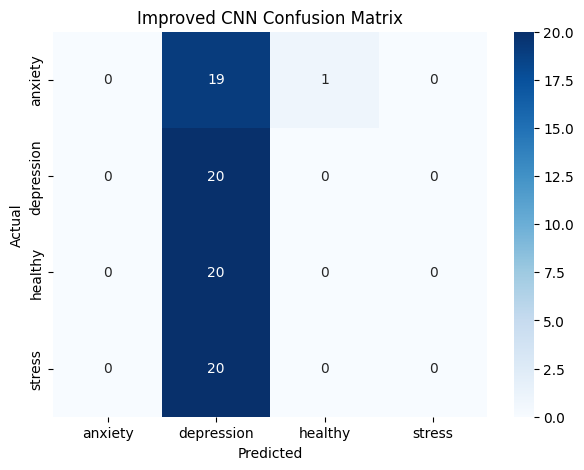

In [85]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
import seaborn as sns
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder_cnn.classes_,
    yticklabels=label_encoder_cnn.classes_
)
plt.title("Improved CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

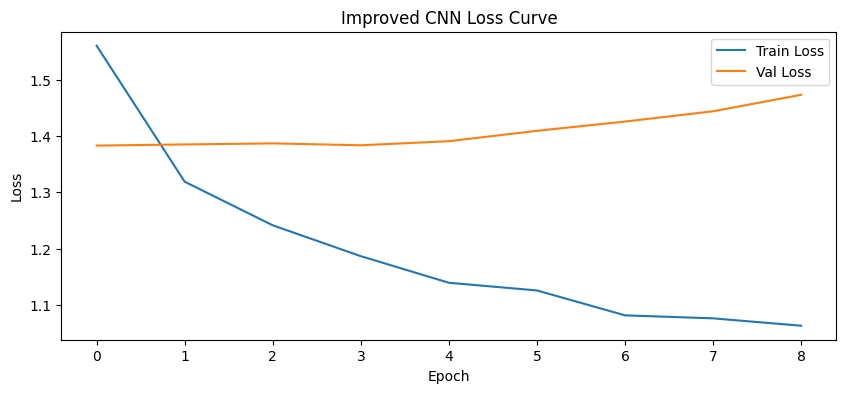

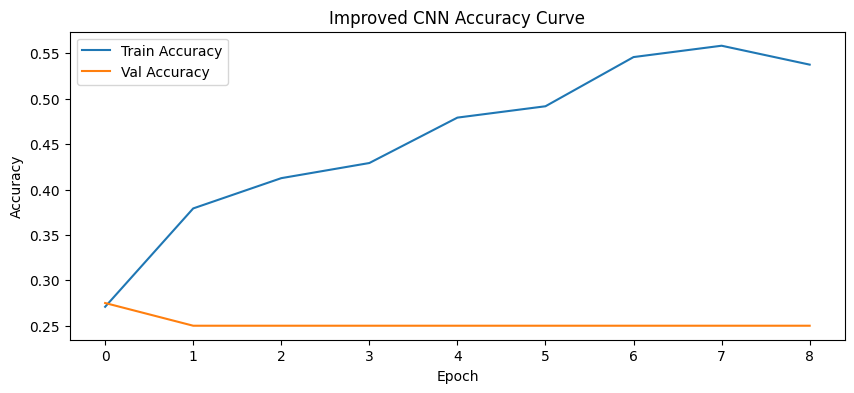

In [86]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("Improved CNN Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.title("Improved CNN Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

**wav2vec2 embeddings + shallow classifier**

In [87]:
!pip install -q transformers torchaudio sentencepiece

In [88]:
import os
import numpy as np
import pandas as pd
import librosa
import torch
from tqdm import tqdm

from transformers import Wav2Vec2Processor, Wav2Vec2Model

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import matplotlib.pyplot as plt
import seaborn as sns

**Load metadata**

In [89]:
processed_meta_path = "/content/drive/MyDrive/ser_project/metadata/processed_metadata.csv"
processed_df = pd.read_csv(processed_meta_path)

print(processed_df.shape)
processed_df.head()

(400, 12)


,original_filepath,processed_filepath,filename,emotion_label,clinical_label,sample_rate,original_duration_sec,trimmed_duration_sec,final_duration_sec,original_num_samples,trimmed_num_samples,final_num_samples
0,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F10_A010.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300
1,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F11_A011.wav,Angry,anxiety,44100,2.000000,1.988390,3.0,88200,87688,132300
2,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F12_A012.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300
3,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F13_A013.wav,Angry,anxiety,44100,2.000000,1.988390,3.0,88200,87688,132300
4,/content/drive/MyDrive/ser_dataset/Angry/SM1_F...,/content/drive/MyDrive/ser_project/preprocesse...,SM1_F14_A014.wav,Angry,anxiety,44100,3.003537,3.003537,3.0,132456,132456,132300


**Load wav2vec2 model**

In [90]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

MODEL_NAME = "facebook/wav2vec2-base"

processor = Wav2Vec2Processor.from_pretrained(MODEL_NAME)
wav2vec_model = Wav2Vec2Model.from_pretrained(MODEL_NAME).to(device)
wav2vec_model.eval()

Using device: cuda


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/380M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/380M [00:00<?, ?B/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Wav2Vec2Model(
  (feature_extractor): Wav2Vec2FeatureEncoder(
    (conv_layers): ModuleList(
      (0): Wav2Vec2GroupNormConvLayer(
        (conv): Conv1d(1, 512, kernel_size=(10,), stride=(5,), bias=False)
        (activation): GELUActivation()
        (layer_norm): GroupNorm(512, 512, eps=1e-05, affine=True)
      )
      (1-4): 4 x Wav2Vec2NoLayerNormConvLayer(
        (conv): Conv1d(512, 512, kernel_size=(3,), stride=(2,), bias=False)
        (activation): GELUActivation()
      )
      (5-6): 2 x Wav2Vec2NoLayerNormConvLayer(
        (conv): Conv1d(512, 512, kernel_size=(2,), stride=(2,), bias=False)
        (activation): GELUActivation()
      )
    )
  )
  (feature_projection): Wav2Vec2FeatureProjection(
    (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
    (projection): Linear(in_features=512, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): Wav2Vec2Encoder(
    (pos_conv_embed): Wav2Vec2PositionalConvEmbedding(
  

**Embedding extraction function**

In [ ]:
TARGET_SR_W2V = 16000

def extract_wav2vec2_embedding(filepath, target_sr=TARGET_SR_W2V):
   
    y, sr = librosa.load(filepath, sr=target_sr)

    # processor prepares tensor
    inputs = processor(
        y,
        sampling_rate=target_sr,
        return_tensors="pt",
        padding=True
    )

    input_values = inputs.input_values.to(device)
    attention_mask = inputs.attention_mask.to(device) if "attention_mask" in inputs else None

    with torch.no_grad():
        outputs = wav2vec_model(input_values, attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state  # shape: [1, time, hidden_size]

   
    embedding = hidden_states.mean(dim=1).squeeze().cpu().numpy()

    return embedding

**Test on one file first**

In [92]:
sample_path = processed_df.iloc[0]["processed_filepath"]
sample_emb = extract_wav2vec2_embedding(sample_path)

print("Embedding shape:", sample_emb.shape)
print(sample_emb[:10])

Embedding shape: (768,)
[-0.07099922 -0.00515607  0.09817889  0.27285093  0.33918452 -0.17380647
  0.246919   -0.2538728   0.00683589  0.00739948]


**Build wav2vec2 embedding dataset**

In [93]:
embedding_rows = []

for _, row in tqdm(processed_df.iterrows(), total=len(processed_df)):
    try:
        emb = extract_wav2vec2_embedding(row["processed_filepath"])

        emb_dict = {f"w2v_{i}": emb[i] for i in range(len(emb))}
        emb_dict["filename"] = row["filename"]
        emb_dict["emotion_label"] = row["emotion_label"]
        emb_dict["clinical_label"] = row["clinical_label"]

        embedding_rows.append(emb_dict)

    except Exception as e:
        print("Error processing:", row["filename"], "|", e)

w2v_df = pd.DataFrame(embedding_rows)

print("w2v_df shape:", w2v_df.shape)
w2v_df.head()

100%|██████████| 400/400 [00:20<00:00, 19.73it/s]


w2v_df shape: (400, 771)


,w2v_0,w2v_1,w2v_2,w2v_3,w2v_4,w2v_5,w2v_6,w2v_7,w2v_8,w2v_9,...,w2v_761,w2v_762,w2v_763,w2v_764,w2v_765,w2v_766,w2v_767,filename,emotion_label,clinical_label
0,-0.070999,-0.005156,0.098179,0.272851,0.339185,-0.173806,0.246919,-0.253873,0.006836,0.007399,...,-0.064231,-0.382388,-0.049186,-0.174265,0.348664,0.194413,-0.344312,SM1_F10_A010.wav,Angry,anxiety
1,-0.019219,-0.018223,0.045962,0.274564,0.224593,-0.267487,0.213415,-0.268692,-0.257290,-0.013566,...,-0.061507,-0.448844,-0.048969,-0.208969,0.320219,0.237303,-0.328461,SM1_F11_A011.wav,Angry,anxiety
2,-0.010763,-0.017508,0.150141,0.252686,0.138640,-0.180529,0.190242,-0.200497,-0.063560,-0.004732,...,-0.130871,-0.351717,-0.034387,-0.203204,0.397856,0.259476,-0.319912,SM1_F12_A012.wav,Angry,anxiety
3,-0.072922,0.080425,0.079243,0.216020,0.251987,-0.179172,0.290001,-0.231327,-0.105408,-0.029982,...,-0.094943,-0.441223,-0.039857,-0.195441,0.350376,0.243270,-0.270962,SM1_F13_A013.wav,Angry,anxiety
4,-0.104935,0.063022,0.042120,0.354396,0.304715,-0.172089,0.195592,-0.187052,0.003533,0.000898,...,-0.023705,-0.305240,-0.096120,-0.213339,0.431790,0.278975,-0.350692,SM1_F14_A014.wav,Angry,anxiety


**Save embeddings**

In [94]:
w2v_path = "/content/drive/MyDrive/ser_project/wav2vec2_embeddings.csv"
w2v_df.to_csv(w2v_path, index=False)

print("Saved wav2vec2 embeddings to:", w2v_path)

Saved wav2vec2 embeddings to: /content/drive/MyDrive/ser_project/wav2vec2_embeddings.csv


**Prepare X and y**

In [95]:
df_w2v_model = w2v_df.copy()

non_feature_cols = ["filename", "emotion_label", "clinical_label"]
w2v_feature_cols = [col for col in df_w2v_model.columns if col not in non_feature_cols]

X_w2v = df_w2v_model[w2v_feature_cols]
y_w2v = df_w2v_model["clinical_label"]

label_encoder_w2v = LabelEncoder()
y_w2v_encoded = label_encoder_w2v.fit_transform(y_w2v)

print("Target classes:", list(label_encoder_w2v.classes_))
print("X_w2v shape:", X_w2v.shape)
print("y_w2v shape:", y_w2v_encoded.shape)

Target classes: ['anxiety', 'depression', 'healthy', 'stress']
X_w2v shape: (400, 768)
y_w2v shape: (400,)


**Train/test split**

In [96]:
X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v = train_test_split(
    X_w2v, y_w2v_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_w2v_encoded
)

print("Train shape:", X_train_w2v.shape)
print("Test shape:", X_test_w2v.shape)

Train shape: (320, 768)
Test shape: (80, 768)


**Define shallow classifiers**

In [97]:
w2v_models = {
    "LogisticRegression_w2v": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=3000, random_state=42))
    ]),

    "SVM_RBF_w2v": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", probability=True, random_state=42))
    ]),

    "RandomForest_w2v": RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ),

    "XGBoost_w2v": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42
    )
}

**Train and compare**

In [98]:
w2v_results = []
trained_w2v_models = {}

for name, model in w2v_models.items():
    print(f"Training {name}...")

    model.fit(X_train_w2v, y_train_w2v)
    y_pred = model.predict(X_test_w2v)

    acc = accuracy_score(y_test_w2v, y_pred)
    prec = precision_score(y_test_w2v, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test_w2v, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test_w2v, y_pred, average="weighted", zero_division=0)

    w2v_results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1_Score": f1
    })

    trained_w2v_models[name] = model

w2v_results_df = pd.DataFrame(w2v_results).sort_values("F1_Score", ascending=False).reset_index(drop=True)

print("\nWav2Vec2 Model Comparison:")
print(w2v_results_df)

Training LogisticRegression_w2v...
Training SVM_RBF_w2v...
Training RandomForest_w2v...
Training XGBoost_w2v...

Wav2Vec2 Model Comparison:
                    Model  Accuracy  Precision  Recall  F1_Score
0  LogisticRegression_w2v    0.8750   0.884137  0.8750  0.876948
1             SVM_RBF_w2v    0.8375   0.848026  0.8375  0.839403
2        RandomForest_w2v    0.8250   0.834868  0.8250  0.826583
3             XGBoost_w2v    0.7750   0.783365  0.7750  0.777590


**Plot wav2vec2 model comparison**

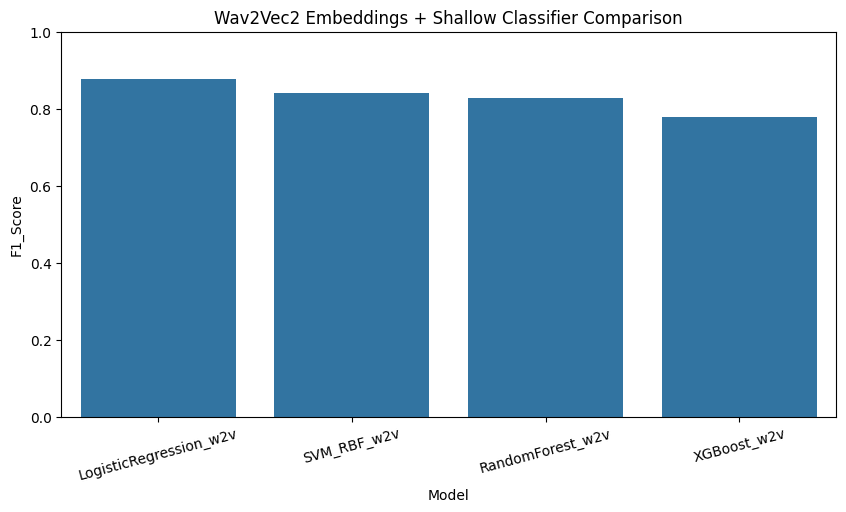

In [99]:
plt.figure(figsize=(10, 5))
sns.barplot(data=w2v_results_df, x="Model", y="F1_Score")
plt.title("Wav2Vec2 Embeddings + Shallow Classifier Comparison")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()

**Detailed evaluation of best wav2vec2 model**

In [100]:
best_w2v_model_name = w2v_results_df.iloc[0]["Model"]
best_w2v_model = trained_w2v_models[best_w2v_model_name]

y_pred_best_w2v = best_w2v_model.predict(X_test_w2v)

print("Best wav2vec2 model:", best_w2v_model_name)
print("\nClassification Report:\n")
print(classification_report(
    y_test_w2v,
    y_pred_best_w2v,
    target_names=label_encoder_w2v.classes_
))

Best wav2vec2 model: LogisticRegression_w2v

Classification Report:

              precision    recall  f1-score   support

     anxiety       1.00      0.95      0.97        20
  depression       0.84      0.80      0.82        20
     healthy       0.75      0.90      0.82        20
      stress       0.94      0.85      0.89        20

    accuracy                           0.88        80
   macro avg       0.88      0.88      0.88        80
weighted avg       0.88      0.88      0.88        80



**Confusion matrix**

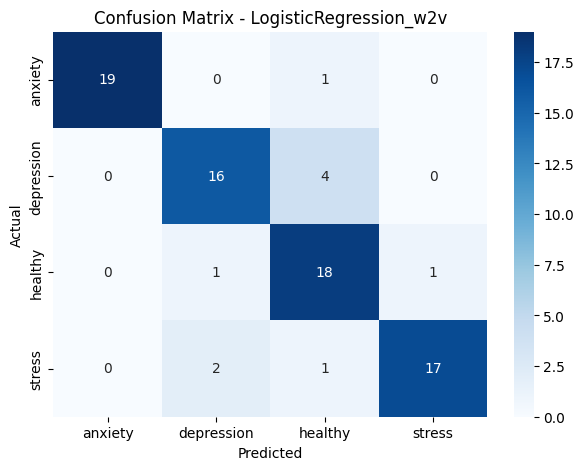

In [101]:
cm_w2v = confusion_matrix(y_test_w2v, y_pred_best_w2v)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_w2v,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder_w2v.classes_,
    yticklabels=label_encoder_w2v.classes_
)
plt.title(f"Confusion Matrix - {best_w2v_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**Cross-validation on best wav2vec2 model**

In [102]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_w2v = cross_val_score(
    best_w2v_model,
    X_w2v,
    y_w2v_encoded,
    cv=cv,
    scoring="f1_weighted"
)

print("Wav2Vec2 CV F1 scores:", cv_scores_w2v)
print("Mean CV F1:", cv_scores_w2v.mean())
print("Std CV F1:", cv_scores_w2v.std())

Wav2Vec2 CV F1 scores: [0.83679976 0.87358793 0.86386346 0.91321505 0.84853433]
Mean CV F1: 0.8672001064716083
Std CV F1: 0.026237015284824722


CNN-based models failed due to overfitting and poor generalization on the small dataset. However, pretrained wav2vec2 embeddings improved performance significantly

**Final Results Table**

In [103]:
final_summary_df = pd.DataFrame({
    "Model": [
        "SVM_RBF (Handcrafted Features) - FINAL",
        "LogisticRegression (wav2vec2 embeddings)",
        "RandomForest (wav2vec2 embeddings)",
        "SVM_RBF (wav2vec2 embeddings)",
        "XGBoost (wav2vec2 embeddings)",
        "CNN (Spectrogram - Failed)"
    ],
    "F1_Score": [
        0.913383,
        0.876948,
        0.826583,
        0.839403,
        0.777590,
        0.35
    ],
    "Remarks": [
        "Best overall performance",
        "Strong pretrained embedding model",
        "Moderate performance",
        "Good but weaker than LR",
        "Lowest among wav2vec2 models",
        "Severe overfitting, rejected"
    ]
})

summary_path = "/content/drive/MyDrive/ser_project/final_model_comparison_updated.csv"
final_summary_df.to_csv(summary_path, index=False)

print(final_summary_df)

                                      Model  F1_Score  \
0    SVM_RBF (Handcrafted Features) - FINAL  0.913383   
1  LogisticRegression (wav2vec2 embeddings)  0.876948   
2        RandomForest (wav2vec2 embeddings)  0.826583   
3             SVM_RBF (wav2vec2 embeddings)  0.839403   
4             XGBoost (wav2vec2 embeddings)  0.777590   
5                CNN (Spectrogram - Failed)  0.350000   

                             Remarks  
0           Best overall performance  
1  Strong pretrained embedding model  
2               Moderate performance  
3            Good but weaker than LR  
4       Lowest among wav2vec2 models  
5       Severe overfitting, rejected  


**Save wav2vec2 best model**

In [104]:
import joblib

best_w2v_model = trained_w2v_models["LogisticRegression_w2v"]

joblib.dump(best_w2v_model, "/content/drive/MyDrive/ser_project/best_w2v_model.pkl")
joblib.dump(label_encoder_w2v, "/content/drive/MyDrive/ser_project/w2v_label_encoder.pkl")
joblib.dump(w2v_feature_cols, "/content/drive/MyDrive/ser_project/w2v_feature_cols.pkl")

['/content/drive/MyDrive/ser_project/w2v_feature_cols.pkl']

In [105]:
import os
import joblib

save_dir = "/content/drive/MyDrive/ser_project"
os.makedirs(save_dir, exist_ok=True)

feature_cols_path = os.path.join(save_dir, "final_feature_columns.pkl")
joblib.dump(feature_cols, feature_cols_path)

print("Saved feature columns at:", feature_cols_path)
print("Number of feature columns:", len(feature_cols))
print("First 10 columns:", feature_cols[:10])

Saved feature columns at: /content/drive/MyDrive/ser_project/final_feature_columns.pkl
Number of feature columns: 73
First 10 columns: ['mfcc_0_mean', 'mfcc_0_std', 'mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std']
